# Práctica DL para Finanzas — Activos adicionales para el agente: ETH, SOL y XRP
**Misma metodología que BTC/USDT, aplicada por separado a ETHUSDT, SOLUSDT y XRPUSDT (velas diarias de MEXC spot)**

El protocolo (bloque 14) pide que, si el agente usa un activo nuevo, se conserve la metodología y se **entrene y valide con los datos de ese activo y un periodo de prueba independiente**, sin reutilizar pesos ni escalas de otro activo sin evaluarlos. Este notebook repite, para cada activo, el flujo que ya se hizo con BTC en los avances 1 a 5:

| Paso | Igual que en BTC | Sección |
|---|---|---|
| Evidencia de la T4 | `nvidia-smi`, operación en `/GPU:0`, versiones | 1 |
| Descarga del crudo de MEXC en bloques de 200 días, con SHA-256 | Avance 1 | 2 |
| Auditoría (vela abierta, orden, duplicados, precios no válidos, hora de corte, huecos, extremos, mínimo de 1,500 observaciones), ficha y diccionario | Avance 1 | 3 |
| Pruebas controladas de errores en una copia pequeña | Avance 2 | 3.1 |
| Objetivo $y_t = P_{t+1}/P_t - 1$, 20 rendimientos de entrada, partición 70/15/15 por fecha del objetivo y fila de control | Avance 1 | 4 |
| Escaladores ajustados solo con TR; pronóstico cero y regresión lineal | Avances 1 y 2 | 5 |
| Filtro técnico "cierre > SMA20" calculado solo con historia hasta $t$ | Avance 5 | 6 |
| LSTM: 10, 20 y 40 neuronas elegidas con RMSE de VA, la mejor repetida con 3 semillas (ensamble) | Avance 2 | 7 |
| δ entre cinco cuantiles de las predicciones en TR y estrategia C (solo pronóstico) o D (pronóstico + SMA20), elegidos con VA | Avances 3 y 5 | 8 |
| Configuración congelada con SHA-256 **antes** de abrir TE; TE evaluado **una sola vez** | Avance 5 | 9 y 10 |
| Recarga desde Drive, pronóstico del siguiente día y paquete para el agente | Avance 5 | 11 a 13 |

**Qué no se repite y por qué.** Solo se entrena la familia LSTM (la red del agente), sin el MLP, y el indicador se usa únicamente como filtro (en BTC, como variable de entrada no mejoró más que el ruido entre semillas). Las ventanas expansivas del capítulo 9 tampoco se repiten. Es una decisión de alcance: los activos adicionales son una ampliación opcional, y lo obligatorio (TR/VA/TE propios, selección con VA y TE único) sí se cumple.

**Antes de ejecutar:**
1. `Entorno de ejecución → Cambiar tipo de entorno → GPU T4`. Sin T4 el notebook se detiene antes de entrenar.
2. Debe existir `MyDrive/DL_Finanzas` (la carpeta del proyecto de BTC). Todo lo de este notebook se guarda en `MyDrive/DL_Finanzas/activos_extra/`, **sin tocar** los archivos de BTC.
3. `Entorno de ejecución → Ejecutar todas`. La primera ejecución descarga, entrena y evalúa TE (unos 10 a 15 minutos). Las siguientes reutilizan el crudo y los modelos guardados y solo **reproducen** TE.

**No cambien `REENTRENAR = False` después de la primera ejecución:** volver a entrenar en la GPU cambia los pesos (no determinismo) y el notebook se detendría para proteger TE.

## 0. Entorno, configuración, versiones y bitácora

In [1]:
# === 0.1 Montar Drive y crear carpetas persistentes ===
import os, sys, json, time, random, hashlib, platform, subprocess, warnings
from datetime import datetime, timezone
from pathlib import Path

try:
    from google.colab import drive
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/DL_Finanzas')
else:
    BASE = Path(os.environ.get('DL_FIN_BASE', './DL_Finanzas'))

BASE_EXTRA = BASE / 'activos_extra'
DIRS_COMUN = {'evidencia': BASE_EXTRA / 'evidencia_t4', 'bitacora': BASE_EXTRA / 'bitacora', 'resultados': BASE_EXTRA / 'resultados'}
for carpeta in DIRS_COMUN.values():
    carpeta.mkdir(parents=True, exist_ok=True)
print('En Colab:', EN_COLAB)
print('Carpeta del proyecto:', BASE.resolve())
print('Carpeta de los activos adicionales:', BASE_EXTRA.resolve())

Mounted at /content/drive
En Colab: True
Carpeta del proyecto: /content/drive/MyDrive/DL_Finanzas
Carpeta de los activos adicionales: /content/drive/MyDrive/DL_Finanzas/activos_extra


In [2]:
# === 0.2 Librerías, configuración, semilla y versiones ===
import numpy as np
import pandas as pd
import requests, joblib, sklearn, matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.ticker import MaxNLocator
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from IPython.display import display

CONFIG = {
    # --- Activos: pares spot de MEXC (base → moneda base) ---
    'ACTIVOS': {'ETHUSDT': 'ETH', 'SOLUSDT': 'SOL', 'XRPUSDT': 'XRP'},
    'MERCADO': 'Criptomonedas',
    'MONEDA_COTIZADA': 'USDT',
    'INTERVALO': '1d',
    'FUENTE': 'MEXC Spot API v3, endpoint público GET /api/v3/klines',
    'URL_KLINES': 'https://api.mexc.com/api/v3/klines',
    'INICIO_DESCARGA_UTC': '2017-01-01',   # se piden velas desde aquí; MEXC devuelve las que tenga
    'REUTILIZAR_CRUDO': True,              # True: si ya existe el crudo guardado, se reutiliza (fechas TR/VA/TE fijas)
    'MIN_OBS': 1500,
    'HUECO_MAX_DIAS': 7,                   # un hueco mayor separa bloques: se usa solo el bloque continuo más reciente
    # --- Objetivo y partición: idénticos a BTC ---
    'N_REZAGOS': 20,
    'PROP_TR': 0.70,
    'PROP_VA': 0.15,                       # TE = resto (15 %)
    'SEMILLA': 42,
    # --- Redes (protocolo del Avance 2) ---
    'REQUIERE_T4': True,                   # sin T4 se detiene el entrenamiento profundo (regla del protocolo)
    'PERDIDA': 'mean_squared_error',
    'OPTIMIZADOR': 'Adam',
    'TASA_APRENDIZAJE': 1e-3,
    'LOTE': 32,
    'MAX_EPOCAS': 300,
    'PACIENCIA': 25,                       # épocas sin mejorar la pérdida de VA antes de detener
    'NEURONAS_CANDIDATAS': [10, 20, 40],   # solo cambia el número de neuronas
    'SEMILLAS': [42, 123, 2024],           # repetición de la mejor configuración
    'REENTRENAR': False,                   # False: si los modelos ya existen en Drive, se cargan (TE reproducible)
    # --- Señal y simulación (Avances 3 y 5) ---
    'CUANTILES_UMBRAL': [0.10, 0.25, 0.50, 0.75, 0.90],   # δ = cuantiles de las predicciones en TR
    'UMBRALES_RESPALDO': [0.0005, 0.001, 0.002, 0.003, 0.005],  # solo si no hay predicciones positivas en TR
    'CAPITAL_INICIAL': 100_000,            # USDT, igual que en BTC
    'COSTO': 0.001,                        # 0.10 % por compra y por venta (supuesto académico, igual que en BTC)
    'UMBRAL_CASI_CONSTANTE': 0.05,         # desv(predicción)/desv(real) en VA por debajo de esto = casi constante
    # --- Pronóstico futuro ---
    'DESCARGAR_DATOS_RECIENTES': True,
    'DIAS_RECIENTES': 150,
    'META_RENDIMIENTO_TE': 0.20,           # +20 % del profesor: solo se reporta, nunca se usa para elegir
}
ACTIVOS = list(CONFIG['ACTIVOS'])
SEMILLA = CONFIG['SEMILLA']
N = CONFIG['N_REZAGOS']
INTV = CONFIG['INTERVALO']
FEATS = [f'ret_lag_{k}' for k in range(N)]
random.seed(SEMILLA)
np.random.seed(SEMILLA)
os.environ['PYTHONHASHSEED'] = str(SEMILLA)

import tensorflow as tf
import keras
from keras import layers
tf.get_logger().setLevel('ERROR')         # oculta avisos repetitivos de retracing en predict; los errores se siguen mostrando
info_build = tf.sysconfig.get_build_info()
VERSIONES = {
    'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
    'scikit-learn': sklearn.__version__, 'matplotlib': matplotlib.__version__, 'requests': requests.__version__,
    'tensorflow': tf.__version__, 'keras': keras.__version__,
    'cuda_build': info_build.get('cuda_version', 'n/d'), 'cudnn_build': info_build.get('cudnn_version', 'n/d'),
    'plataforma': platform.platform(), 'semilla_base': SEMILLA,
    'fecha_ejecucion_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
}
with open(DIRS_COMUN['resultados'] / 'versiones_entorno_activos_extra.json', 'w') as f:
    json.dump(VERSIONES, f, indent=2)

def dirs_activo(sim):
    'Carpetas de cada activo, con la misma estructura que la carpeta de BTC.'
    raiz = BASE_EXTRA / sim
    d = {k: raiz / v for k, v in {'crudos': 'datos/originales', 'procesados': 'datos/procesados', 'modelos': 'modelos',
                                   'resultados': 'resultados', 'figuras': 'figuras'}.items()}
    for c in d.values():
        c.mkdir(parents=True, exist_ok=True)
    return d
DIRS_ACT = {sim: dirs_activo(sim) for sim in ACTIVOS}
pd.Series(VERSIONES)

,0
python,3.13.16
numpy,2.4.6
pandas,2.2.3
scikit-learn,1.6.1
matplotlib,3.10.0
requests,2.32.4
tensorflow,2.21.0
keras,3.13.2
cuda_build,12.5.1
cudnn_build,9


In [3]:
# === 0.3 Excepciones específicas y bitácora de errores ===
# Regla: nada de "except: pass". Cada error se captura por tipo, se explica y se registra.
class ErrorPractica(Exception):
    'Error base de la práctica.'
class DescargaError(ErrorPractica):
    'La fuente no respondió o respondió con un error.'
class DatosVaciosError(ErrorPractica):
    'No hay datos, o no alcanzan el mínimo requerido.'
class FechaDuplicadaError(ErrorPractica):
    'Fechas repetidas que no se pueden resolver con la regla documentada.'
class ValorInvalidoError(ErrorPractica):
    'Valores no finitos, no positivos o archivo alterado.'
class DimensionError(ErrorPractica):
    'Formas o columnas distintas a las esperadas.'
class FugaInformacionError(ErrorPractica):
    'Se detectó uso de información futura o del conjunto reservado.'
class ParticionDistintaError(ErrorPractica):
    'Archivos guardados que ya no coinciden con lo que se recalcula (crudo, partición o escaladores).'
class EntrenamientoError(ErrorPractica):
    'Fallo del entrenamiento (pérdida no finita, pesos no restaurados, GPU no usada).'

RUTA_BITACORA = DIRS_COMUN['bitacora'] / 'bitacora_errores_activos_extra.csv'

def registrar_evento(etapa, error, causa, accion, verificacion):
    'Agrega una fila: fecha | etapa | error | causa | acción correctiva | resultado de la verificación.'
    fila = pd.DataFrame([{
        'fecha': datetime.now(timezone.utc).isoformat(timespec='seconds'),
        'etapa': etapa, 'error': error, 'causa': causa,
        'accion_correctiva': accion, 'resultado_verificacion': verificacion,
    }])
    fila.to_csv(RUTA_BITACORA, mode='a', header=not RUTA_BITACORA.exists(), index=False)
    print(f'[BITÁCORA] {etapa} | {error} | {causa} | {accion} | {verificacion}')

# Estado de cada activo. Si un activo falla en una etapa obligatoria, se excluye con su motivo
# (queda en la bitácora) y los demás continúan.
ACT = {sim: {} for sim in ACTIVOS}
EXCLUIDOS = {}
def vigentes():
    return [s for s in ACTIVOS if s not in EXCLUIDOS]
def excluir(sim, etapa, e, accion):
    EXCLUIDOS[sim] = f'{etapa}: {type(e).__name__}: {e}'
    registrar_evento(f'{sim} · {etapa}', type(e).__name__, str(e)[:300], accion, f'{sim} excluido del resto del notebook')

## 1. Evidencia obligatoria de la GPU T4

Igual que en BTC: se guarda la salida de `nvidia-smi`, se comprueba que TensorFlow reconoce la GPU y se ejecuta una multiplicación de matrices **en la GPU**, registrando el dispositivo efectivo, el tiempo y las versiones. Si no hay T4, el incidente queda en la bitácora y el entrenamiento profundo (sección 7) se detiene.

In [4]:
# === 1. Evidencia de T4 ===
def verificar_t4():
    ts = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    ev = {'fecha_utc': ts, 'entorno_colab': EN_COLAB, 'semilla': SEMILLA}
    try:
        salida = subprocess.run(['nvidia-smi'], capture_output=True, text=True, timeout=30, check=True).stdout
        print(salida)
        (DIRS_COMUN['evidencia'] / f'nvidia_smi_{ts}.txt').write_text(salida)
        consulta = subprocess.run(['nvidia-smi', '--query-gpu=name,driver_version,memory.total', '--format=csv,noheader'],
                                  capture_output=True, text=True, timeout=30, check=True).stdout.strip()
        ev['nvidia_smi_gpu'] = consulta
    except FileNotFoundError:
        ev['nvidia_smi_gpu'] = 'nvidia-smi no existe: el entorno no tiene GPU NVIDIA'
    except subprocess.CalledProcessError as e:
        ev['nvidia_smi_gpu'] = f'nvidia-smi falló: {e.stderr.strip()}'
    except subprocess.TimeoutExpired:
        ev['nvidia_smi_gpu'] = 'nvidia-smi no respondió en 30 s'

    tf.random.set_seed(SEMILLA)
    ev['tensorflow'] = tf.__version__
    ev['tf_construido_con_cuda'] = bool(tf.test.is_built_with_cuda())
    gpus = tf.config.list_physical_devices('GPU')
    ev['tf_gpus'] = [g.name for g in gpus]
    ev['operacion_dispositivo'] = 'sin GPU'
    if gpus:
        detalles = tf.config.experimental.get_device_details(gpus[0])
        ev['tf_nombre_gpu'] = detalles.get('device_name', '')
        ev['compute_capability'] = str(detalles.get('compute_capability', ''))
        with tf.device('/GPU:0'):
            a = tf.random.normal((4000, 4000))
            _ = tf.matmul(a, a).numpy()            # calentamiento
            t0 = time.perf_counter()
            c = tf.matmul(a, a)
            _ = c.numpy()                          # fuerza la sincronización
            ev['matmul_4000x4000_s'] = round(time.perf_counter() - t0, 4)
        ev['operacion_dispositivo'] = c.device
    nombre = f"{ev.get('tf_nombre_gpu', '')} {ev.get('nvidia_smi_gpu', '')}"
    ev['T4_OK'] = ('T4' in nombre) and ('GPU' in ev['operacion_dispositivo'])
    with open(DIRS_COMUN['evidencia'] / f'evidencia_t4_{ts}.json', 'w') as f:
        json.dump(ev, f, indent=2)
    if not ev['T4_OK']:
        registrar_evento('entorno', 'T4 ausente o GPU no utilizada', f"GPU detectada: {nombre.strip() or 'ninguna'}",
                         'No se entrena la LSTM; reprogramar sesión con T4.', 'pendiente')
    return ev

EVIDENCIA_T4 = verificar_t4()
print(json.dumps(EVIDENCIA_T4, indent=2))
print('\n>>> T4 verificada y usada por TensorFlow:', EVIDENCIA_T4['T4_OK'])

Wed Nov 18 01:36:32 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   33C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Descarga de datos originales (MEXC)

- Velas **diarias cerradas** del endpoint público de MEXC (no requiere clave), la misma función que BTC (descarga v2).
- MEXC entrega como máximo ~500 velas por solicitud, así que se piden bloques de 200 días con `startTime` y `endTime`; si un bloque llega incompleto se continúa desde la última vela. Reintentos limitados con espera creciente; un error 4xx detiene la descarga con un mensaje que dice qué revisar.
- El crudo de cada activo se guarda **tal como llega**, con sus metadatos (fecha de descarga, parámetros y SHA-256).
- Con `REUTILIZAR_CRUDO = True`, las siguientes ejecuciones cargan el mismo archivo y verifican su huella: así TR, VA y TE no se mueven cada día.
- Si un activo falla, se informa fuente, activo y causa, se registra en la bitácora y ese activo se excluye; los demás continúan.

In [5]:
# === 2. Descarga o carga del archivo crudo ===
COLS_MEXC = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume']
MS_DIA = 86_400_000

def sha256_archivo(ruta):
    h = hashlib.sha256()
    with open(ruta, 'rb') as f:
        for bloque in iter(lambda: f.read(1 << 20), b''):
            h.update(bloque)
    return h.hexdigest()

def _get_json(url, params, max_reintentos=5, espera_inicial=1.0):
    espera, ultimo_error = espera_inicial, None
    for intento in range(1, max_reintentos + 1):
        try:
            r = requests.get(url, params=params, timeout=20)
        except (requests.exceptions.Timeout, requests.exceptions.ConnectionError) as e:
            ultimo_error = f'{type(e).__name__}: {e}'
        else:
            if r.status_code == 429 or r.status_code >= 500:
                ultimo_error = f'HTTP {r.status_code}: {r.text[:200]}'
            elif r.status_code >= 400:
                raise DescargaError(f'MEXC rechazó la solicitud {params}: HTTP {r.status_code} {r.text[:300]}. '
                                    'Revise el símbolo (ej. ETHUSDT) y el intervalo (1d).')
            else:
                try:
                    return r.json()
                except ValueError as e:
                    raise DescargaError(f'MEXC no devolvió JSON válido: {r.text[:200]}') from e
        print(f'  intento {intento}/{max_reintentos} fallido ({ultimo_error}); nuevo intento en {espera:.0f} s')
        time.sleep(espera)
        espera *= 2
    raise DescargaError(f'Sin respuesta válida de MEXC tras {max_reintentos} intentos. Último error: {ultimo_error}')

def descargar_klines_mexc(simbolo, intervalo, inicio_utc, dias_por_bloque=200, pausa=0.25):
    # MEXC entrega como máximo ~500 velas por solicitud aunque se pidan 1000: bloques de 200 días con continuación.
    ahora_ms = int(time.time() * 1000)
    s = int(pd.Timestamp(inicio_utc, tz='UTC').timestamp() * 1000)
    filas, solicitudes, incompletos = [], 0, []
    while s < ahora_ms:
        e = min(s + dias_por_bloque * MS_DIA - 1, ahora_ms)
        datos = _get_json(CONFIG['URL_KLINES'], {'symbol': simbolo, 'interval': intervalo,
                                                 'startTime': s, 'endTime': e, 'limit': 1000})
        solicitudes += 1
        if not isinstance(datos, list):
            raise DescargaError(f'MEXC devolvió un objeto inesperado (¿error?): {str(datos)[:300]}')
        if datos:
            filas.extend(datos)
            ultimo_open = max(int(k[0]) for k in datos)
            primero_open = min(int(k[0]) for k in datos)
            if filas and len(filas) > len(datos) and primero_open - s > 2 * MS_DIA:
                incompletos.append(f"{pd.to_datetime(s, unit='ms').date()}: faltan velas al inicio del bloque")
            siguiente = ultimo_open + MS_DIA
            if ultimo_open + MS_DIA <= e:
                print(f"  {pd.to_datetime(s, unit='ms').date()} → {pd.to_datetime(ultimo_open, unit='ms').date()}: "
                      f"{len(datos)} velas (bloque incompleto, se continúa desde ahí)")
            else:
                print(f"  {pd.to_datetime(s, unit='ms').date()} → {pd.to_datetime(e, unit='ms').date()}: {len(datos)} velas")
            s = max(siguiente, s + MS_DIA)
        else:
            s = e + 1
        time.sleep(pausa)
    if not filas:
        raise DatosVaciosError(f'MEXC no devolvió velas para {simbolo} {intervalo} desde {inicio_utc}. '
                               'Verifique que el par existe en MEXC spot y la conectividad.')
    if incompletos:
        print('ADVERTENCIA: posibles bloques truncados por la API:', incompletos)
    anchos = {len(f) for f in filas}
    if min(anchos) < 7:
        raise DimensionError(f'Velas con {sorted(anchos)} campos; se esperaban al menos 7 (open_time … close_time).')
    df = pd.DataFrame([f[:8] for f in filas])
    df.columns = COLS_MEXC[:df.shape[1]]
    return df, {'descarga_ms': ahora_ms, 'bloques': solicitudes, 'avisos_truncamiento': incompletos}

def obtener_crudo(sim):
    D = DIRS_ACT[sim]
    arch, arch_meta = D['crudos'] / f'{sim}_{INTV}_mexc_crudo.csv', D['crudos'] / f'{sim}_{INTV}_mexc_crudo_meta.json'
    if CONFIG['REUTILIZAR_CRUDO'] and arch.exists() and arch_meta.exists():
        meta = json.load(open(arch_meta))
        if sha256_archivo(arch) != meta['sha256']:
            raise ValorInvalidoError(f'{arch.name} no coincide con su SHA-256 registrado: el crudo fue modificado. '
                                     'Restaure el original o descargue de nuevo con REUTILIZAR_CRUDO=False.')
        print(f"{sim}: crudo reutilizado ({arch.name}, descargado {meta['fecha_descarga_utc']}), SHA-256 verificado")
        return pd.read_csv(arch), meta, arch
    if arch.exists():                       # respaldo: nunca se sobrescribe un crudo previo
        sello = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
        arch.rename(arch.with_name(f'{arch.stem}_respaldo_{sello}.csv'))
        if arch_meta.exists():
            arch_meta.rename(arch_meta.with_name(f'{arch_meta.stem}_respaldo_{sello}.json'))
    print(f'{sim}: descargando de MEXC…')
    crudo, info = descargar_klines_mexc(sim, INTV, CONFIG['INICIO_DESCARGA_UTC'])
    crudo.to_csv(arch, index=False)
    crudo = pd.read_csv(arch)                # se trabaja con el archivo guardado (mismos tipos en todas las ejecuciones)
    meta = {'fuente': CONFIG['FUENTE'], 'url': CONFIG['URL_KLINES'], 'simbolo': sim, 'intervalo': INTV,
            'parametros': {'startTime_inicial': CONFIG['INICIO_DESCARGA_UTC'], 'limit': 1000, 'dias_por_bloque': 200},
            'version_descarga': 2, 'avisos_truncamiento': info['avisos_truncamiento'],
            'fecha_descarga_utc': datetime.fromtimestamp(info['descarga_ms'] / 1000, timezone.utc).isoformat(timespec='seconds'),
            'descarga_ms': info['descarga_ms'], 'bloques': info['bloques'], 'filas_recibidas': len(crudo),
            'columnas': list(crudo.columns), 'zona_horaria': 'Marcas de tiempo en milisegundos Unix (UTC)',
            'sha256': sha256_archivo(arch)}
    with open(arch_meta, 'w') as f:
        json.dump(meta, f, indent=2)
    print(f'{sim}: crudo guardado ({len(crudo)} filas, SHA-256 {meta["sha256"][:12]}…)')
    return crudo, meta, arch

for sim in vigentes():
    try:
        ACT[sim]['crudo'], ACT[sim]['meta'], ACT[sim]['arch_crudo'] = obtener_crudo(sim)
    except (DescargaError, DatosVaciosError, DimensionError, ValorInvalidoError) as e:
        excluir(sim, 'descarga', e, f"Flujo detenido para {sim}. Fuente: {CONFIG['FUENTE']}. Revisar conectividad o símbolo.")
print('\nActivos con crudo:', vigentes(), '| excluidos:', EXCLUIDOS or 'ninguno')

ETHUSDT: descargando de MEXC…
  2017-07-20 → 2018-02-04: 103 velas
  2018-02-05 → 2018-08-24: 201 velas
  2018-08-25 → 2019-03-12: 200 velas
  2019-03-13 → 2019-09-28: 199 velas
  2019-09-29 → 2020-04-15: 200 velas
  2020-04-16 → 2020-11-01: 200 velas
  2020-11-02 → 2021-05-20: 200 velas
  2021-05-21 → 2021-12-06: 200 velas
  2021-12-07 → 2022-06-24: 200 velas
  2022-06-25 → 2023-01-10: 200 velas
  2023-01-11 → 2023-07-29: 200 velas
  2023-07-30 → 2024-02-14: 200 velas
  2024-02-15 → 2024-09-01: 200 velas
  2024-09-02 → 2025-03-20: 200 velas
  2025-03-21 → 2025-10-06: 200 velas
  2025-10-07 → 2026-04-24: 200 velas
  2026-04-25 → 2026-11-10: 200 velas
  2026-11-11 → 2026-11-18: 8 velas
ETHUSDT: crudo guardado (3311 filas, SHA-256 4b319abc62fd…)
SOLUSDT: descargando de MEXC…
  2020-04-15 → 2020-10-31: 116 velas
  2020-11-01 → 2021-05-19: 200 velas
  2021-05-20 → 2021-12-05: 200 velas
  2021-12-06 → 2022-06-23: 200 velas
  2022-06-24 → 2023-01-09: 200 velas
  2023-01-10 → 2023-07-28: 200 

## 3. Auditoría y limpieza de datos

Mismas reglas que en BTC; cada una deja registro de cuántas filas cambia:

| Control | Regla |
|---|---|
| Vela aún abierta | Se elimina la vela cuyo `close_time` es posterior al momento de la descarga. |
| Orden | Se ordena por fecha (orden estable). |
| Fechas duplicadas | Si las filas repetidas son idénticas, se conserva una. Si difieren, **se detiene**. |
| Precios no finitos o ≤ 0 | Se reportan columna y fecha, y la fila se retira. No se imputa con información futura. |
| Hora de corte distinta | Se conservan solo las velas con la hora de apertura vigente. Mezclar cortes daría rendimientos de 16 o 32 horas. |
| Hueco > 7 días | Se usa solo el bloque continuo más reciente. |
| Días faltantes | Se reportan. **No se rellenan.** Las ventanas que crucen un hueco se descartan. |
| Volumen | Se reporta volumen nulo o cero. **No se inventa.** |
| Coherencia OHLC | Se reporta; no se modifica. |
| Valores extremos | Rendimientos con z robusto > 6 (mediana/MAD): se marcan, no se eliminan. |
| Mínimo de observaciones | ≥ 1,500 observaciones válidas por activo; si no, ese activo se excluye. |

In [6]:
# === 3. Auditoría (misma función que BTC) ===
def auditar(crudo, meta, min_obs, hueco_max):
    reg = []
    def anotar(control, filas, accion, detalle=''):
        reg.append({'control': control, 'filas_afectadas': int(filas), 'accion': accion, 'detalle': detalle})

    if crudo is None or crudo.empty:
        raise DatosVaciosError('El archivo crudo está vacío: no hay nada que auditar.')
    requeridas = ['open_time', 'open', 'high', 'low', 'close', 'close_time']
    faltan = [c for c in requeridas if c not in crudo.columns]
    if faltan:
        raise DimensionError(f'Faltan columnas {faltan}. Recibidas: {list(crudo.columns)}')

    df = crudo.copy()
    anotar('Filas recibidas', len(df), 'ninguna')
    num = [c for c in ['open', 'high', 'low', 'close', 'volume', 'quote_volume'] if c in df.columns]
    nan_antes = df[num].isna().sum()
    for c in num:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    no_num = int((df[num].isna().sum() - nan_antes).sum())
    anotar('Valores no numéricos convertidos a NaN', no_num, 'se tratan como no válidos')
    df['open_time'] = pd.to_numeric(df['open_time'], errors='raise').astype('int64')
    df['close_time'] = pd.to_numeric(df['close_time'], errors='raise').astype('int64')

    abierta = df['close_time'] > meta['descarga_ms']
    anotar('Vela no cerrada al descargar', abierta.sum(), 'eliminada',
           ', '.join(pd.to_datetime(df.loc[abierta, 'open_time'], unit='ms').dt.strftime('%Y-%m-%d')))
    df = df.loc[~abierta].copy()

    fecha_utc = pd.to_datetime(df['open_time'], unit='ms', utc=True)
    horas = fecha_utc.dt.strftime('%H:%M UTC').value_counts()
    anotar('Hora de apertura de la vela diaria', 0, 'registrada', horas.to_dict().__repr__())
    df['fecha'] = fecha_utc.dt.tz_convert(None).dt.normalize()

    desorden = int((df['fecha'].diff().dt.total_seconds() < 0).sum())
    df = df.sort_values('fecha', kind='mergesort').reset_index(drop=True)
    anotar('Fechas fuera de orden', desorden, 'reordenadas cronológicamente')

    dup = df.duplicated('fecha', keep=False)
    if dup.any():
        precios_cols = ['open', 'high', 'low', 'close']
        conflicto = [f for f, g in df[dup].groupby('fecha') if (g[precios_cols].nunique() > 1).any()]
        if conflicto:
            raise FechaDuplicadaError(f'{len(conflicto)} fechas repetidas con precios distintos '
                                      f'(ej. {[str(x.date()) for x in conflicto[:3]]}). Revise la fuente; no se elige una al azar.')
    n_dup = int(df.duplicated('fecha').sum())
    df = df.drop_duplicates('fecha', keep='first').reset_index(drop=True)
    anotar('Fechas duplicadas idénticas', n_dup, 'se conservó la primera')

    precios = ['open', 'high', 'low', 'close']
    malos = (~np.isfinite(df[precios])).any(axis=1) | (df[precios] <= 0).any(axis=1)
    det = df.loc[malos, ['fecha'] + precios]
    anotar('Precios no finitos o no positivos', malos.sum(), 'fila retirada (sin imputar)', det.to_dict('records').__repr__()[:500])
    df = df.loc[~malos].reset_index(drop=True)

    if 'volume' in df.columns:
        anotar('Volumen faltante', df['volume'].isna().sum(), 'se conserva sin inventar')
        anotar('Volumen igual a cero', (df['volume'] == 0).sum(), 'se conserva; día sin negociación reportado')

    incoh = ((df['high'] < df[['open', 'close']].max(axis=1)) |
             (df['low'] > df[['open', 'close']].min(axis=1)) | (df['high'] < df['low']))
    anotar('Incoherencia OHLC', incoh.sum(), 'reportada, sin modificar', ', '.join(df.loc[incoh, 'fecha'].dt.strftime('%Y-%m-%d').head(10)))

    hora = pd.to_datetime(df['open_time'], unit='ms', utc=True).dt.strftime('%H:%M')
    hora_vigente = hora.iloc[-1]
    otra_hora = hora != hora_vigente
    anotar('Velas con otra hora de corte', otra_hora.sum(), f'retiradas: se conserva solo la alineación vigente ({hora_vigente} UTC)',
           (f"{df.loc[otra_hora, 'fecha'].min().date()} a {df.loc[otra_hora, 'fecha'].max().date()}" if otra_hora.any() else ''))
    df = df.loc[~otra_hora].reset_index(drop=True)

    salto = df['fecha'].diff() > pd.Timedelta(days=hueco_max)
    if salto.any():
        inicio_bloque = df.loc[salto[salto].index[-1], 'fecha']
        previas = df['fecha'] < inicio_bloque
        anotar(f'Historia anterior a un hueco > {hueco_max} días', previas.sum(), f'retirada: se usa el bloque desde {inicio_bloque.date()}',
               f"{df.loc[previas, 'fecha'].min().date()} a {df.loc[previas, 'fecha'].max().date()}")
        df = df.loc[~previas].reset_index(drop=True)

    rango = pd.date_range(df['fecha'].min(), df['fecha'].max(), freq='D')
    faltantes = rango.difference(df['fecha'])
    anotar('Días faltantes en calendario continuo', len(faltantes), 'no se rellenan', ', '.join(faltantes.strftime('%Y-%m-%d')[:20]))

    r = df['close'] / df['close'].shift(1) - 1
    med = r.median()
    mad = (r - med).abs().median()
    z = 0.6745 * (r - med) / mad if mad > 0 else pd.Series(0.0, index=r.index)
    ext = df.loc[z.abs() > 6, ['fecha']].assign(rendimiento=r[z.abs() > 6].round(4))
    anotar('Rendimientos extremos (|z robusto| > 6)', len(ext), 'marcados, no eliminados', ext.astype(str).to_dict('records').__repr__()[:500])

    if len(df) < min_obs:
        raise DatosVaciosError(f'Solo hay {len(df)} observaciones válidas; el protocolo exige ≥ {min_obs}. '
                               'Elija un activo con más historia o revise la descarga.')
    anotar('Observaciones válidas finales', len(df), f'cumple mínimo de {min_obs}')
    cols = ['fecha', 'open', 'high', 'low', 'close'] + [c for c in ['volume', 'quote_volume'] if c in df.columns] + ['open_time', 'close_time']
    return df[cols], pd.DataFrame(reg), faltantes, ext

pd.set_option('display.max_colwidth', 120)
for sim in vigentes():
    D, a = DIRS_ACT[sim], ACT[sim]
    try:
        a['datos'], a['auditoria'], a['faltantes'], a['extremos'] = auditar(a['crudo'], a['meta'], CONFIG['MIN_OBS'], CONFIG['HUECO_MAX_DIAS'])
    except (DatosVaciosError, DimensionError, FechaDuplicadaError) as e:
        excluir(sim, 'auditoría', e, 'Flujo detenido para este activo antes de construir ventanas')
        continue
    a['auditoria'].to_csv(D['resultados'] / 'auditoria_datos.csv', index=False)
    a['arch_proc'] = D['procesados'] / f'{sim}_{INTV}_procesado.csv'
    a['datos'].to_csv(a['arch_proc'], index=False)
    print(f"\n=== {sim}: {a['datos'].fecha.min().date()} → {a['datos'].fecha.max().date()} | {len(a['datos'])} días válidos ===")
    display(a['auditoria'])
print('Activos que pasan la auditoría:', vigentes(), '| excluidos:', EXCLUIDOS or 'ninguno')


=== ETHUSDT: 2018-08-23 → 2026-11-17 | 3008 días válidos ===


,control,filas_afectadas,accion,detalle
0,Filas recibidas,3311,ninguna,
1,Valores no numéricos convertidos a NaN,0,se tratan como no válidos,
2,Vela no cerrada al descargar,1,eliminada,2026-11-18
3,Hora de apertura de la vela diaria,0,registrada,"{'00:00 UTC': 3008, '16:00 UTC': 302}"
4,Fechas fuera de orden,0,reordenadas cronológicamente,
5,Fechas duplicadas idénticas,0,se conservó la primera,
6,Precios no finitos o no positivos,0,fila retirada (sin imputar),[]
7,Volumen faltante,0,se conserva sin inventar,
8,Volumen igual a cero,0,se conserva; día sin negociación reportado,
9,Incoherencia OHLC,0,"reportada, sin modificar",



=== SOLUSDT: 2020-07-08 → 2026-11-17 | 2324 días válidos ===


,control,filas_afectadas,accion,detalle
0,Filas recibidas,2325,ninguna,
1,Valores no numéricos convertidos a NaN,0,se tratan como no válidos,
2,Vela no cerrada al descargar,1,eliminada,2026-11-18
3,Hora de apertura de la vela diaria,0,registrada,{'00:00 UTC': 2324}
4,Fechas fuera de orden,0,reordenadas cronológicamente,
5,Fechas duplicadas idénticas,0,se conservó la primera,
6,Precios no finitos o no positivos,0,fila retirada (sin imputar),[]
7,Volumen faltante,0,se conserva sin inventar,
8,Volumen igual a cero,0,se conserva; día sin negociación reportado,
9,Incoherencia OHLC,0,"reportada, sin modificar",



=== XRPUSDT: 2019-05-08 → 2026-11-17 | 2751 días válidos ===


,control,filas_afectadas,accion,detalle
0,Filas recibidas,2752,ninguna,
1,Valores no numéricos convertidos a NaN,0,se tratan como no válidos,
2,Vela no cerrada al descargar,1,eliminada,2026-11-18
3,Hora de apertura de la vela diaria,0,registrada,{'00:00 UTC': 2751}
4,Fechas fuera de orden,0,reordenadas cronológicamente,
5,Fechas duplicadas idénticas,0,se conservó la primera,
6,Precios no finitos o no positivos,0,fila retirada (sin imputar),[]
7,Volumen faltante,0,se conserva sin inventar,
8,Volumen igual a cero,0,se conserva; día sin negociación reportado,
9,Incoherencia OHLC,0,"reportada, sin modificar",


Activos que pasan la auditoría: ['ETHUSDT', 'SOLUSDT', 'XRPUSDT'] | excluidos: ninguno


In [7]:
# === 3.0 Ficha de cada activo y diccionario de datos ===
for sim in vigentes():
    D, a = DIRS_ACT[sim], ACT[sim]
    base_m, cot = CONFIG['ACTIVOS'][sim], CONFIG['MONEDA_COTIZADA']
    a['ficha'] = {
        'Mercado': CONFIG['MERCADO'], 'Activo (par)': f'{base_m}/{cot} ({sim})', 'Moneda base': base_m,
        'Moneda cotizada (precios)': cot, 'Plataforma de origen': 'MEXC (mercado spot)', 'Fuente': a['meta'].get('fuente'),
        'Fecha de descarga (UTC)': a['meta'].get('fecha_descarga_utc'),
        'Periodo procesado': f"{a['datos'].fecha.min().date()} a {a['datos'].fecha.max().date()}",
        'Observaciones válidas': len(a['datos']), 'Frecuencia': 'Diaria',
        'Zona horaria': 'UTC; cada vela se identifica por la fecha UTC de su apertura',
        'Calendario': 'Continuo 24/7 (sin días inhábiles); los huecos se reportan y no se rellenan',
        'Ajustes de precio': 'No aplica: las criptomonedas no pagan dividendos ni tienen particiones; precios sin ajustar',
        'Volumen': f'Reportado por MEXC: volume en {base_m} y quote_volume en {cot}; no se inventa ni se rellena',
        'SHA-256 del crudo': a['meta'].get('sha256'),
    }
    with open(D['resultados'] / 'ficha_activo.json', 'w') as f:
        json.dump(a['ficha'], f, indent=2, ensure_ascii=False, default=str)
    pd.DataFrame([
        ('fecha', 'Fecha UTC de apertura de la vela diaria', 'fecha', '-', 'derivada de open_time'),
        ('open', 'Precio de apertura', 'float', cot, 'MEXC'), ('high', 'Precio máximo del día', 'float', cot, 'MEXC'),
        ('low', 'Precio mínimo del día', 'float', cot, 'MEXC'), ('close', 'Precio de cierre (Pₜ)', 'float', cot, 'MEXC'),
        ('volume', 'Volumen negociado', 'float', base_m, 'MEXC'),
        ('quote_volume', 'Volumen negociado en moneda cotizada', 'float', cot, 'MEXC'),
        ('open_time / close_time', 'Inicio y fin de la vela', 'int (ms Unix)', 'UTC', 'MEXC'),
        ('ret_lag_k', 'Rendimiento simple r_{t-k} = P_{t-k}/P_{t-k-1} − 1, k = 0..19', 'float', 'proporción', 'calculada'),
        ('y', 'Objetivo yₜ = Pₜ₊₁/Pₜ − 1', 'float', 'proporción', 'calculada'),
        ('sma20 / dist_sma20', 'Media de los 20 cierres hasta t (incluye t) y Cₜ/SMA20ₜ − 1; solo como filtro', 'float', f'{cot} / proporción', 'calculada'),
    ], columns=['variable', 'descripcion', 'tipo', 'unidad', 'origen']).to_csv(D['resultados'] / 'diccionario_datos.csv', index=False)
display(pd.DataFrame({sim: ACT[sim]['ficha'] for sim in vigentes()}))

,ETHUSDT,SOLUSDT,XRPUSDT
Mercado,Criptomonedas,Criptomonedas,Criptomonedas
Activo (par),ETH/USDT (ETHUSDT),SOL/USDT (SOLUSDT),XRP/USDT (XRPUSDT)
Moneda base,ETH,SOL,XRP
Moneda cotizada (precios),USDT,USDT,USDT
Plataforma de origen,MEXC (mercado spot),MEXC (mercado spot),MEXC (mercado spot)
Fuente,"MEXC Spot API v3, endpoint público GET /api/v3/klines","MEXC Spot API v3, endpoint público GET /api/v3/klines","MEXC Spot API v3, endpoint público GET /api/v3/klines"
Fecha de descarga (UTC),2026-11-18T01:36:34+00:00,2026-11-18T01:36:43+00:00,2026-11-18T01:36:50+00:00
Periodo procesado,2018-08-23 a 2026-11-17,2020-07-08 a 2026-11-17,2019-05-08 a 2026-11-17
Observaciones válidas,3008,2324,2751
Frecuencia,Diaria,Diaria,Diaria


### 3.1 Pruebas controladas de errores (copia pequeña)

Se provocan los fallos que pide el protocolo en una **copia de 150 velas** del primer activo vigente: conjunto vacío, fecha duplicada con precios distintos, valores no válidos y dimensiones incorrectas. Se muestra el mensaje y se comprueba la detención o recuperación esperada. El crudo original no se toca (su SHA-256 se verifica al final).

In [8]:
# === 3.1 Pruebas controladas ===
def verificar_formas(nombre, X, y, forma_esperada):
    'Detiene antes de entrenar si la forma no es la esperada. forma_esperada usa None para el número de ejemplos.'
    X, y = np.asarray(X), np.asarray(y)
    if len(X) == 0 or len(y) == 0:
        raise DatosVaciosError(f'{nombre}: el conjunto está vacío (X={X.shape}, y={y.shape}).')
    if X.ndim != len(forma_esperada) or any(e is not None and r != e for r, e in zip(X.shape, forma_esperada)):
        esperada = '(' + ', '.join('ejemplos' if e is None else str(e) for e in forma_esperada) + ')'
        raise DimensionError(f'{nombre}: forma esperada {esperada}, recibida {X.shape}. '
                             'Revise el número de rezagos y el reshape (ejemplos × pasos × variables para LSTM).')
    if len(X) != len(y):
        raise DimensionError(f'{nombre}: {len(X)} ejemplos en X y {len(y)} en y.')
    if not (np.isfinite(X).all() and np.isfinite(y).all()):
        raise ValorInvalidoError(f'{nombre}: hay valores no finitos; revise la auditoría y el escalado.')

PRUEBAS = []
if vigentes():
    sim_p = vigentes()[0]
    copia = ACT[sim_p]['crudo'].tail(150).reset_index(drop=True).copy()
    meta_p = ACT[sim_p]['meta']
    def probar(nombre, funcion, esperado):
        try:
            funcion()
            resultado, mensaje = 'sin excepción', ''
        except ErrorPractica as e:
            resultado, mensaje = type(e).__name__, str(e)
        ok = resultado == esperado if esperado != 'recuperación' else resultado == 'sin excepción'
        PRUEBAS.append({'activo': sim_p, 'prueba': nombre, 'esperado': esperado, 'obtenido': resultado,
                        'correcto': ok, 'mensaje': mensaje[:200]})
        print(f"{'✔' if ok else '✘'} {nombre}: {resultado} {('— ' + mensaje[:140]) if mensaje else ''}")

    probar('Conjunto vacío', lambda: auditar(copia.iloc[0:0], meta_p, 100, 7), 'DatosVaciosError')
    dup = pd.concat([copia, copia.iloc[[10]].assign(close=copia.loc[10, 'close'] * 1.5)], ignore_index=True)
    probar('Fecha duplicada con precios distintos', lambda: auditar(dup, meta_p, 100, 7), 'FechaDuplicadaError')
    mala = copia.copy()
    mala.loc[20, 'close'], mala.loc[21, 'low'] = -5.0, np.inf
    def recuperar():
        limpio, aud, _, _ = auditar(mala, meta_p, 100, 7)
        n_ret = int(aud.loc[aud.control == 'Precios no finitos o no positivos', 'filas_afectadas'].iloc[0])
        if n_ret != 2 or not np.isfinite(limpio[['open', 'high', 'low', 'close']]).all().all() or (limpio[['open', 'high', 'low', 'close']] <= 0).any().any():
            raise ValorInvalidoError('La recuperación no retiró las 2 filas no válidas.')
    probar('Precio negativo e infinito (2 filas retiradas sin imputar)', recuperar, 'recuperación')
    probar('LSTM con 19 rezagos', lambda: verificar_formas('prueba', np.zeros((50, 19, 1)), np.zeros(50), (None, N, 1)), 'DimensionError')
    probar('LSTM sin eje de variables', lambda: verificar_formas('prueba', np.zeros((50, N)), np.zeros(50), (None, N, 1)), 'DimensionError')
    sha_ok = sha256_archivo(ACT[sim_p]['arch_crudo']) == meta_p['sha256']
    print(f"{'✔' if sha_ok else '✘'} SHA-256 del crudo de {sim_p} sin cambios después de las pruebas")
    PRUEBAS = pd.DataFrame(PRUEBAS)
    PRUEBAS.to_csv(DIRS_COMUN['resultados'] / 'pruebas_controladas_activos_extra.csv', index=False)
    for _, p in PRUEBAS.iterrows():
        registrar_evento('prueba controlada', p['prueba'], f'Fallo provocado en una copia de 150 velas de {sim_p}',
                         f"Respuesta esperada: {p['esperado']}", ('correcto' if p['correcto'] else 'INCORRECTO') + f"; obtenido {p['obtenido']}")
    if not (PRUEBAS['correcto'].all() and sha_ok):
        raise ErrorPractica('Alguna prueba controlada no se comportó como se esperaba: revisar antes de continuar.')

✔ Conjunto vacío: DatosVaciosError — El archivo crudo está vacío: no hay nada que auditar.
✔ Fecha duplicada con precios distintos: FechaDuplicadaError — 1 fechas repetidas con precios distintos (ej. ['2026-07-02']). Revise la fuente; no se elige una al azar.
✔ Precio negativo e infinito (2 filas retiradas sin imputar): sin excepción 
✔ LSTM con 19 rezagos: DimensionError — prueba: forma esperada (ejemplos, 20, 1), recibida (50, 19, 1). Revise el número de rezagos y el reshape (ejemplos × pasos × variables para 
✔ LSTM sin eje de variables: DimensionError — prueba: forma esperada (ejemplos, 20, 1), recibida (50, 20). Revise el número de rezagos y el reshape (ejemplos × pasos × variables para LST
✔ SHA-256 del crudo de ETHUSDT sin cambios después de las pruebas
[BITÁCORA] prueba controlada | Conjunto vacío | Fallo provocado en una copia de 150 velas de ETHUSDT | Respuesta esperada: DatosVaciosError | correcto; obtenido DatosVaciosError
[BITÁCORA] prueba controlada | Fecha duplicada con 

## 4. Objetivo, ventanas y separación TR–VA–TE (por fecha del objetivo)

- Rendimiento conocido al cierre de $t$: $r_t = P_t/P_{t-1} - 1$. Entradas: $r_t, r_{t-1}, \dots, r_{t-19}$ (`ret_lag_0` … `ret_lag_19`).
- Objetivo: $y_t = P_{t+1}/P_t - 1$, con $P_{t+1}$ el cierre del **siguiente día del calendario**.
- Se descartan filas sin objetivo observable, objetivos que cruzan un hueco y ventanas que contienen un hueco. Nada se rellena.
- Partición **de cada activo**: primer 70 % → TR, siguiente 15 % → VA, último 15 % → TE, después de construir las ventanas y sin barajar. Como cada activo tiene su propia historia en MEXC, sus fechas de corte son distintas a las de BTC.

In [9]:
# === 4. Ventanas y partición ===
UN_DIA = pd.Timedelta(days=1)

def construir_ejemplos(datos):
    d = datos[['fecha', 'close']].copy().reset_index(drop=True)
    d['ret'] = d['close'] / d['close'].shift(1) - 1
    d['ret_consecutivo'] = d['fecha'].diff() == UN_DIA
    d['fecha_objetivo'] = d['fecha'].shift(-1)
    d['close_siguiente'] = d['close'].shift(-1)
    d['y'] = d['close_siguiente'] / d['close'] - 1
    d['objetivo_valido'] = (d['fecha_objetivo'] - d['fecha']) == UN_DIA
    for k in range(N):
        d[f'ret_lag_{k}'] = d['ret'].shift(k)
    d['ventana_valida'] = d['ret_consecutivo'].astype(int).rolling(N).sum() == N
    d['fecha_primer_cierre'] = d['fecha'].shift(N)
    finitas = np.isfinite(d[FEATS + ['y']]).all(axis=1)
    validas = d['objetivo_valido'] & d['ventana_valida'] & finitas
    motivos = {'filas procesadas': len(d), 'sin objetivo observable o que cruza un hueco': int((~d['objetivo_valido']).sum()),
               'ventana incompleta (inicio de la serie o hueco)': int((~d['ventana_valida']).sum()), 'ejemplos válidos': int(validas.sum())}
    ds = (d.loc[validas, ['fecha_primer_cierre', 'fecha', 'fecha_objetivo'] + FEATS + ['y', 'close', 'close_siguiente']]
            .rename(columns={'fecha': 'fecha_emision'}).sort_values('fecha_objetivo').reset_index(drop=True))
    if not ds['fecha_objetivo'].is_unique or not ds['fecha_objetivo'].is_monotonic_increasing:
        raise FechaDuplicadaError('Las fechas objetivo no son únicas o no están ordenadas.')
    if not ((ds['fecha_objetivo'] - ds['fecha_emision']) == UN_DIA).all():
        raise FugaInformacionError('Hay ejemplos cuyo objetivo no es el siguiente día.')
    return d, ds, motivos

def particionar(ds):
    n = len(ds)
    n_tr, n_va = int(np.floor(n * CONFIG['PROP_TR'])), int(np.floor(n * CONFIG['PROP_VA']))
    n_te = n - n_tr - n_va
    if min(n_tr, n_va, n_te) <= 0:
        raise DimensionError(f'Partición vacía: TR={n_tr}, VA={n_va}, TE={n_te}. Revise el número de ejemplos ({n}).')
    ds = ds.copy()
    ds['conjunto'] = ['TR'] * n_tr + ['VA'] * n_va + ['TE'] * n_te
    TR, VA, TE = (ds[ds.conjunto == c].reset_index(drop=True) for c in ('TR', 'VA', 'TE'))
    if not TR['fecha_objetivo'].max() < VA['fecha_objetivo'].min():
        raise FugaInformacionError('El último objetivo de TR no es anterior al primero de VA.')
    if not VA['fecha_objetivo'].max() < TE['fecha_objetivo'].min():
        raise FugaInformacionError('El último objetivo de VA no es anterior al primero de TE.')
    part = pd.DataFrame([{'conjunto': nombre, 'n_ejemplos': len(p), 'proporcion': round(len(p) / n, 4),
                          'primera_emision': p.fecha_emision.min().date(), 'ultima_emision': p.fecha_emision.max().date(),
                          'primer_objetivo': p.fecha_objetivo.min().date(), 'ultimo_objetivo': p.fecha_objetivo.max().date(),
                          'primer_cierre_usado_como_contexto': p.fecha_primer_cierre.min().date()}
                         for nombre, p in (('TR', TR), ('VA', VA), ('TE', TE))])
    return ds, TR, VA, TE, part

for sim in vigentes():
    D, a = DIRS_ACT[sim], ACT[sim]
    try:
        a['d'], ds, motivos = construir_ejemplos(a['datos'])
        a['ds'], a['TR'], a['VA'], a['TE'], a['particiones'] = particionar(ds)
    except (FechaDuplicadaError, FugaInformacionError, DimensionError) as e:
        excluir(sim, 'ventanas y partición', e, 'Flujo detenido para este activo')
        continue
    ruta_part = D['resultados'] / 'particiones.csv'
    if ruta_part.exists():               # en una reejecución la partición debe ser idéntica
        p0 = pd.read_csv(ruta_part).astype(str)
        cols = ['conjunto', 'n_ejemplos', 'primer_objetivo', 'ultimo_objetivo']
        if not p0[cols].reset_index(drop=True).equals(a['particiones'].astype(str)[cols].reset_index(drop=True)):
            e = ParticionDistintaError(f'La partición de {sim} cambió respecto a la guardada: cambió el crudo o la configuración.')
            excluir(sim, 'partición', e, 'Detenido: restaurar el crudo original (verificado por SHA-256)')
            continue
        a['particion_verificada'] = True
    else:
        a['particiones'].to_csv(ruta_part, index=False)
        a['particion_verificada'] = False
    a['ds'].to_csv(D['procesados'] / f'{sim}_{INTV}_ejemplos_ventanas.csv', index=False)
    print(f'\n=== {sim} ===  ' + ' | '.join(f'{k}: {v}' for k, v in motivos.items()))
    print('✔ último objetivo TR < primer objetivo VA   ✔ último objetivo VA < primer objetivo TE'
          + ('   ✔ partición idéntica a la guardada' if a['particion_verificada'] else ''))
    display(a['particiones'])


=== ETHUSDT ===  filas procesadas: 3008 | sin objetivo observable o que cruza un hueco: 2 | ventana incompleta (inicio de la serie o hueco): 40 | ejemplos válidos: 2966
✔ último objetivo TR < primer objetivo VA   ✔ último objetivo VA < primer objetivo TE


,conjunto,n_ejemplos,proporcion,primera_emision,ultima_emision,primer_objetivo,ultimo_objetivo,primer_cierre_usado_como_contexto
0,TR,2076,0.6999,2018-09-12,2024-06-09,2018-09-13,2024-06-10,2018-08-23
1,VA,444,0.1497,2024-06-10,2025-08-27,2024-06-11,2025-08-28,2024-05-21
2,TE,446,0.1504,2025-08-28,2026-11-16,2025-08-29,2026-11-17,2025-08-08



=== SOLUSDT ===  filas procesadas: 2324 | sin objetivo observable o que cruza un hueco: 1 | ventana incompleta (inicio de la serie o hueco): 20 | ejemplos válidos: 2303
✔ último objetivo TR < primer objetivo VA   ✔ último objetivo VA < primer objetivo TE


,conjunto,n_ejemplos,proporcion,primera_emision,ultima_emision,primer_objetivo,ultimo_objetivo,primer_cierre_usado_como_contexto
0,TR,1612,0.7000,2020-07-28,2024-12-25,2020-07-29,2024-12-26,2020-07-08
1,VA,345,0.1498,2024-12-26,2025-12-05,2024-12-27,2025-12-06,2024-12-06
2,TE,346,0.1502,2025-12-06,2026-11-16,2025-12-07,2026-11-17,2025-11-16



=== XRPUSDT ===  filas procesadas: 2751 | sin objetivo observable o que cruza un hueco: 1 | ventana incompleta (inicio de la serie o hueco): 20 | ejemplos válidos: 2730
✔ último objetivo TR < primer objetivo VA   ✔ último objetivo VA < primer objetivo TE


,conjunto,n_ejemplos,proporcion,primera_emision,ultima_emision,primer_objetivo,ultimo_objetivo,primer_cierre_usado_como_contexto
0,TR,1910,0.6996,2019-05-28,2024-08-18,2019-05-29,2024-08-19,2019-05-08
1,VA,409,0.1498,2024-08-19,2025-10-01,2024-08-20,2025-10-02,2024-07-30
2,TE,411,0.1505,2025-10-02,2026-11-16,2025-10-03,2026-11-17,2025-09-12


In [10]:
# === 4.1 Control de aprendizaje: una fila completa por activo ===
for sim in vigentes():
    a = ACT[sim]
    fila = a['VA'].iloc[0]
    datos = a['datos']
    cierres_entrada = datos[(datos.fecha >= fila.fecha_primer_cierre) & (datos.fecha <= fila.fecha_emision)][['fecha', 'close']]
    rets = cierres_entrada['close'].pct_change().dropna().to_numpy()[::-1]       # r_t, r_{t-1}, ...
    ok_lags = len(rets) == N and np.allclose(rets, fila[FEATS].to_numpy(dtype=float))
    ok_fechas = cierres_entrada.fecha.max() <= fila.fecha_emision < fila.fecha_objetivo
    print(f'{sim}: cierres de entrada {fila.fecha_primer_cierre.date()} → {fila.fecha_emision.date()} ({len(cierres_entrada)} cierres = {N} rendimientos) | '
          f'emisión {fila.fecha_emision.date()} | objetivo {fila.fecha_objetivo.date()} | '
          f'y = {fila.close_siguiente:,.4f} / {fila.close:,.4f} − 1 = {fila.y:+.6f}')
    if not (ok_lags and ok_fechas):
        raise FugaInformacionError(f'{sim}: la fila de control no coincide con los precios o usa fechas posteriores a la emisión.')
print('\n✔ En cada activo los 20 rezagos coinciden con los precios y todas las entradas son ≤ fecha de emisión.')
print('  El modelo no conoce la respuesta: P_{t+1} solo aparece en la etiqueta y nunca en las entradas.')

ETHUSDT: cierres de entrada 2024-05-21 → 2024-06-10 (21 cierres = 20 rendimientos) | emisión 2024-06-10 | objetivo 2024-06-11 | y = 3,497.3400 / 3,667.8500 − 1 = -0.046488
SOLUSDT: cierres de entrada 2024-12-06 → 2024-12-26 (21 cierres = 20 rendimientos) | emisión 2024-12-26 | objetivo 2024-12-27 | y = 184.2300 / 188.4700 − 1 = -0.022497
XRPUSDT: cierres de entrada 2024-07-30 → 2024-08-19 (21 cierres = 20 rendimientos) | emisión 2024-08-19 | objetivo 2024-08-20 | y = 0.5940 / 0.5983 − 1 = -0.007187

✔ En cada activo los 20 rezagos coinciden con los precios y todas las entradas son ≤ fecha de emisión.
  El modelo no conoce la respuesta: P_{t+1} solo aparece en la etiqueta y nunca en las entradas.


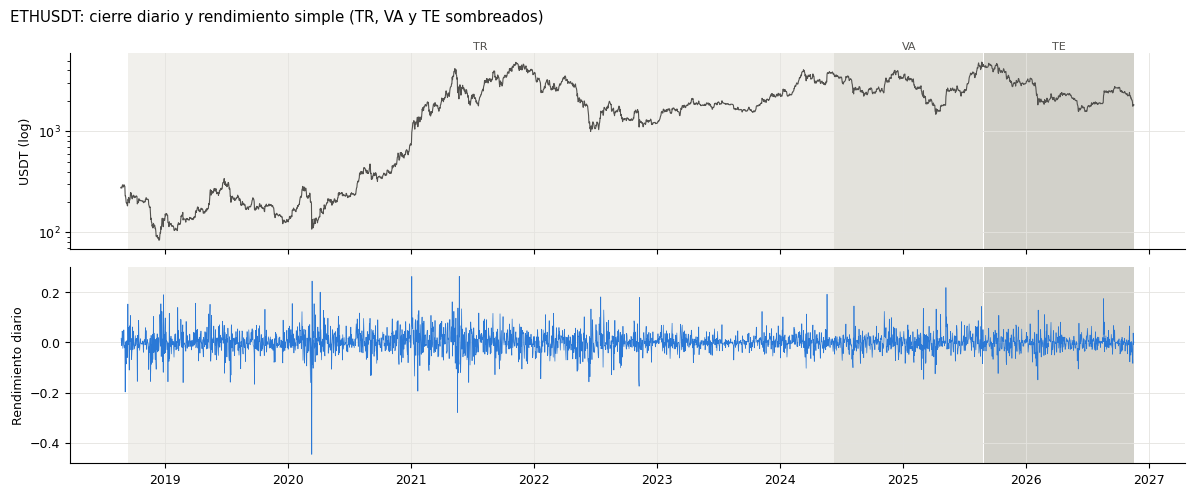

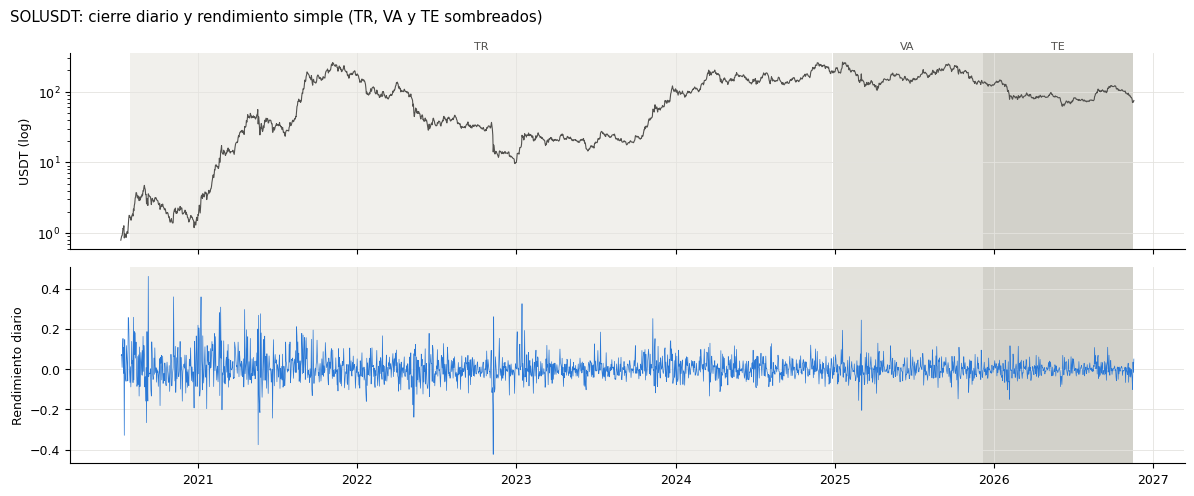

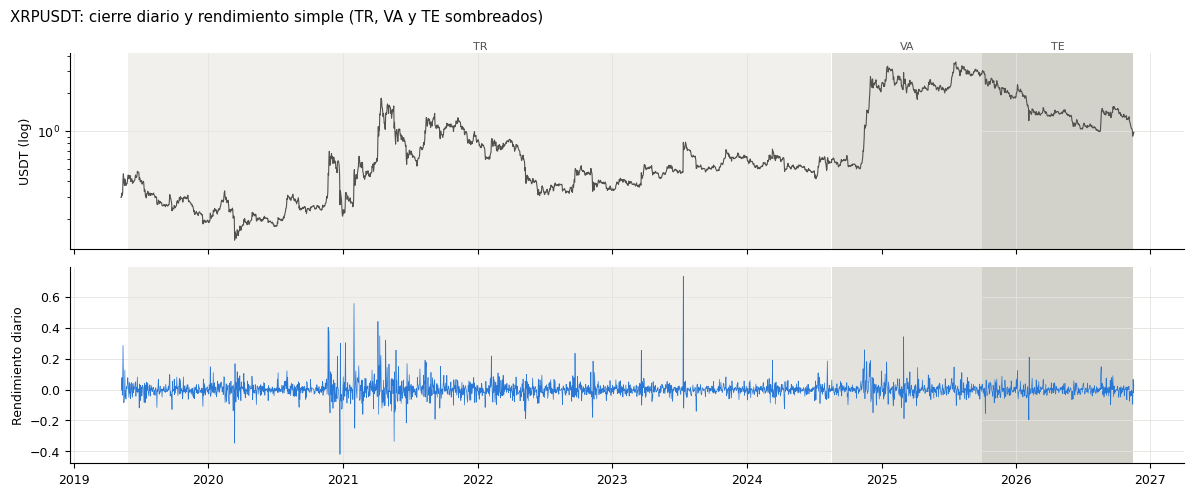

,activo,serie,estadistico_ADF,p_valor,conclusion (5%)
0,ETHUSDT,cierre (precio),-1.0607,0.730503,no estacionaria
1,ETHUSDT,rendimiento diario,-13.8543,0.000000,estacionaria
2,SOLUSDT,cierre (precio),-1.8024,0.379290,no estacionaria
3,SOLUSDT,rendimiento diario,-8.3819,0.000000,estacionaria
4,XRPUSDT,cierre (precio),-3.0048,0.034445,estacionaria
5,XRPUSDT,rendimiento diario,-45.9525,0.000000,estacionaria


In [11]:
# === 4.2 Estacionariedad (ADF solo con TR) y gráfica de precio y rendimientos ===
try:
    from statsmodels.tsa.stattools import adfuller
except ImportError as e:
    adfuller = None
    registrar_evento('estacionariedad', 'statsmodels no disponible', str(e), 'Instalar con pip install statsmodels', 'ADF omitida')

TINTA2, AZUL, NARANJA, GRIS, REJILLA = '#52514e', '#2a78d6', '#eb6834', '#9a9893', '#e4e3df'
TONOS = {'TR': '#f1f0ec', 'VA': '#e3e2dc', 'TE': '#d2d1ca'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': REJILLA, 'grid.linewidth': 0.6, 'font.size': 9})
def sombrear(ax, a, rotular=False):
    for nombre in ('TR', 'VA', 'TE'):
        p = a[nombre]
        x0, x1 = p.fecha_emision.min(), p.fecha_emision.max()
        ax.axvspan(x0, x1, color=TONOS[nombre], zorder=0, lw=0)
        if rotular:
            ax.text(x0 + (x1 - x0) / 2, 1.01, nombre, transform=ax.get_xaxis_transform(), ha='center', va='bottom', color=TINTA2, fontsize=8)

filas_adf = []
for sim in vigentes():
    a, D = ACT[sim], DIRS_ACT[sim]
    serie_tr = a['d'][a['d']['fecha'] <= a['TR']['fecha_objetivo'].max()]
    if adfuller is not None:
        for nombre, serie in (('cierre (precio)', serie_tr['close']), ('rendimiento diario', serie_tr['ret'].dropna())):
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', FutureWarning)
                est, pval, *_ = adfuller(serie.to_numpy(), autolag='AIC')
            filas_adf.append({'activo': sim, 'serie': nombre, 'estadistico_ADF': round(est, 4), 'p_valor': round(pval, 6),
                              'conclusion (5%)': 'estacionaria' if pval < 0.05 else 'no estacionaria'})
    fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    sombrear(axes[0], a, True)
    axes[0].plot(a['datos'].fecha, a['datos'].close, color=TINTA2, lw=0.8)
    axes[0].set_yscale('log'); axes[0].set_ylabel(f"{CONFIG['MONEDA_COTIZADA']} (log)")
    sombrear(axes[1], a)
    axes[1].plot(a['d'].fecha, a['d'].ret, color=AZUL, lw=0.5); axes[1].set_ylabel('Rendimiento diario')
    fig.suptitle(f'{sim}: cierre diario y rendimiento simple (TR, VA y TE sombreados)', x=0.01, ha='left')
    fig.tight_layout(); fig.savefig(D['figuras'] / 'precio_rendimientos.png', dpi=150, bbox_inches='tight'); plt.show()
if filas_adf:
    ADF = pd.DataFrame(filas_adf)
    for sim in vigentes():
        ADF[ADF.activo == sim].to_csv(DIRS_ACT[sim]['resultados'] / 'adf_TR.csv', index=False)
    display(ADF)

## 5. Escaladores ajustados solo con TR y modelos de referencia

- `StandardScaler` de los 20 rezagos y del objetivo $y$, ajustados **solo con TR** de cada activo. VA y TE se transforman sin reajustar. No se usan las escalas de BTC.
- Referencias obligatorias, en las mismas fechas de VA: **pronóstico cero** y **regresión lineal** con los mismos 20 rezagos.
- Métricas idénticas a BTC: error = estimado − real; MAE, RMSE, precisión direccional (los casos con real o estimado igual a cero se excluyen del denominador; si queda en cero, es *no definida*), correlación y *model bias*.
- En una reejecución, los escaladores guardados deben coincidir con los recalculados; si no, el notebook se detiene.

In [12]:
# === 5. Escaladores, métricas y referencias ===
def precision_direccional(y, yhat):
    sy, sp = np.sign(y), np.sign(yhat)
    m = (sy != 0) & (sp != 0)
    return (float((sy[m] == sp[m]).mean()) if m.any() else np.nan), int(m.sum())

def model_bias(yhat):
    alcistas, bajistas = int((yhat > 0).sum()), int((yhat < 0).sum())
    return (alcistas / bajistas if bajistas > 0 else np.nan), alcistas, bajistas

def correlacion(y, yhat):
    return float(np.corrcoef(y, yhat)[0, 1]) if np.ptp(yhat) > 0 and np.ptp(y) > 0 else np.nan

def metricas(y, yhat):
    y, yhat = np.asarray(y, float).ravel(), np.asarray(yhat, float).ravel()
    if y.shape != yhat.shape:
        raise DimensionError(f'y {y.shape} y predicción {yhat.shape} tienen formas distintas.')
    if len(y) == 0:
        raise DatosVaciosError('No hay ejemplos para evaluar.')
    if not np.isfinite(yhat).all():
        raise ValorInvalidoError('Predicciones no finitas: revisar escalas, datos e hiperparámetros.')
    e = yhat - y
    pdir, ndir = precision_direccional(y, yhat)
    mb, alc, baj = model_bias(yhat)
    return {'MAE': float(np.mean(np.abs(e))), 'RMSE': float(np.sqrt(np.mean(e ** 2))),
            'prec_direccional': pdir, 'n_direccional': ndir, 'correlacion': correlacion(y, yhat),
            'model_bias': mb, 'senales_alcistas': alc, 'senales_bajistas': baj, 'n': len(y)}

def registrar_experimentos(sim, filas):
    ruta = DIRS_ACT[sim]['resultados'] / 'experimentos.csv'
    nuevo = pd.DataFrame(filas)
    if ruta.exists():
        prev = pd.read_csv(ruta)
        clave_n = set(zip(nuevo['id'], nuevo['conjunto']))
        prev = prev[[(i, c) not in clave_n for i, c in zip(prev['id'], prev['conjunto'])]]
        nuevo = pd.concat([prev, nuevo], ignore_index=True)
    nuevo.to_csv(ruta, index=False)

def a_secuencia(X):
    'Columnas ret_lag_0..ret_lag_19 (reciente→antiguo) a secuencia antiguo→reciente con 1 variable (mismo contrato que BTC).'
    return np.ascontiguousarray(X[:, ::-1]).reshape(-1, X.shape[1], 1).astype('float32')

def mismo_escalador(e1, e2):
    return np.allclose(e1.mean_, e2.mean_, rtol=0, atol=0) and np.allclose(e1.scale_, e2.scale_, rtol=0, atol=0) and e1.n_samples_seen_ == e2.n_samples_seen_

def escalador_guardado(nuevo, ruta, nombre, sim):
    'Guarda el escalador la primera vez; después exige que el guardado sea idéntico al recalculado con TR.'
    if ruta.exists():
        previo = joblib.load(ruta)
        if not mismo_escalador(previo, nuevo):
            raise ParticionDistintaError(f'{sim}: el escalador {nombre} guardado no coincide con el recalculado con TR.')
        return previo
    joblib.dump(nuevo, ruta)
    return nuevo

FILAS_REF = []
for sim in vigentes():
    D, a = DIRS_ACT[sim], ACT[sim]
    X, Y = {}, {}
    for c in ('TR', 'VA', 'TE'):
        X[c], Y[c] = a[c][FEATS].to_numpy(float), a[c]['y'].to_numpy(float)
        if X[c].ndim != 2 or X[c].shape[1] != N or len(X[c]) != len(Y[c]):
            raise DimensionError(f'{sim} {c}: forma esperada (ejemplos, {N}); recibida X={X[c].shape}, y={Y[c].shape}')
        if not (np.isfinite(X[c]).all() and np.isfinite(Y[c]).all()):
            raise ValorInvalidoError(f'{sim} {c} contiene valores no finitos.')
    try:
        esc_x = escalador_guardado(StandardScaler().fit(X['TR']), D['modelos'] / 'escalador_x_rezagos20.joblib', 'x', sim)   # ← único ajuste
        esc_y = escalador_guardado(StandardScaler().fit(Y['TR'].reshape(-1, 1)), D['modelos'] / 'escalador_y.joblib', 'y', sim)
    except ParticionDistintaError as e:
        excluir(sim, 'escaladores', e, 'Detenido: restaurar el crudo original o borrar los modelos y empezar de nuevo (TE no evaluado)')
        continue
    if esc_x.n_samples_seen_ != len(X['TR']) or esc_y.n_samples_seen_ != len(Y['TR']):
        raise FugaInformacionError(f'{sim}: un escalador vio un número de filas distinto a TR.')
    a.update(X=X, Y=Y, esc_x=esc_x, esc_y=esc_y)
    a['Xe'] = {c: esc_x.transform(X[c]) for c in ('TR', 'VA', 'TE')}     # TE se transforma, pero no se predice hasta congelar
    a['a_escala_y'] = (lambda e: (lambda v: e.transform(np.asarray(v).reshape(-1, 1)).ravel()))(esc_y)
    a['a_rendimiento'] = (lambda e: (lambda v: e.inverse_transform(np.asarray(v).reshape(-1, 1)).ravel()))(esc_y)
    a['seq'] = {c: a_secuencia(a['Xe'][c]) for c in ('TR', 'VA', 'TE')}
    seq0, ultimo = a['seq']['VA'][0, :, 0], esc_x.transform(X['VA'][:1])[0]
    if not (np.isclose(seq0[-1], ultimo[0]) and np.isclose(seq0[0], ultimo[N - 1])):
        raise DimensionError(f'{sim}: la secuencia LSTM no está ordenada de antiguo a reciente.')
    # Referencias
    lr = LinearRegression().fit(a['Xe']['TR'], Y['TR'])
    joblib.dump(lr, D['modelos'] / 'regresion_lineal.joblib')
    a['lr'] = lr
    a['pred'] = {'cero': {c: np.zeros(len(Y[c])) for c in ('TR', 'VA')},
                 'regresion_lineal': {c: lr.predict(a['Xe'][c]) for c in ('TR', 'VA')}}
    ahora = datetime.now(timezone.utc).isoformat(timespec='seconds')
    filas = []
    for nombre in ('cero', 'regresion_lineal'):
        for c in ('TR', 'VA'):
            m = metricas(Y[c], a['pred'][nombre][c])
            filas.append({'id': f'{sim}_{nombre}', 'modelo': nombre, 'tipo': 'referencia', 'variables': f'{N} rezagos de rendimiento',
                          'conjunto': c, 'primer_objetivo': a[c].fecha_objetivo.min().date(), 'ultimo_objetivo': a[c].fecha_objetivo.max().date(),
                          **m, 'fecha_ejecucion_utc': ahora})
            if c == 'VA':
                FILAS_REF.append({'activo': sim, 'modelo': nombre, 'RMSE_VA': m['RMSE'], 'MAE_VA': m['MAE'], 'prec_dir_VA': m['prec_direccional']})
    registrar_experimentos(sim, filas)
    ref_va = {f['modelo']: f for f in FILAS_REF if f['activo'] == sim}
    a['meta_dl'] = {'RMSE_VA_a_superar': min(r['RMSE_VA'] for r in ref_va.values()), 'MAE_VA_a_superar': min(r['MAE_VA'] for r in ref_va.values()),
                    'mejor_referencia_RMSE': min(ref_va, key=lambda k: ref_va[k]['RMSE_VA']),
                    'mejor_referencia_MAE': min(ref_va, key=lambda k: ref_va[k]['MAE_VA']),
                    'RMSE_VA_regresion_lineal': ref_va['regresion_lineal']['RMSE_VA'], 'MAE_VA_regresion_lineal': ref_va['regresion_lineal']['MAE_VA']}
    json.dump(a['meta_dl'], open(D['resultados'] / 'meta_para_dl.json', 'w'), indent=2)
    print(f"{sim}: escaladores con {int(esc_x.n_samples_seen_)} filas de TR (= len(TR)); media de VA escalado {a['Xe']['VA'].mean():+.4f} (no es 0: no se reajustó)")
REF = pd.DataFrame(FILAS_REF)
display(REF.round(6))

ETHUSDT: escaladores con 2076 filas de TR (= len(TR)); media de VA escalado -0.0285 (no es 0: no se reajustó)
SOLUSDT: escaladores con 1612 filas de TR (= len(TR)); media de VA escalado -0.0855 (no es 0: no se reajustó)
XRPUSDT: escaladores con 1910 filas de TR (= len(TR)); media de VA escalado +0.0622 (no es 0: no se reajustó)


,activo,modelo,RMSE_VA,MAE_VA,prec_dir_VA
0,ETHUSDT,cero,0.038442,0.026999,NaN
1,ETHUSDT,regresion_lineal,0.038514,0.027280,0.527027
2,SOLUSDT,cero,0.046140,0.033771,NaN
3,SOLUSDT,regresion_lineal,0.046882,0.034756,0.470930
4,XRPUSDT,cero,0.049323,0.031085,NaN
5,XRPUSDT,regresion_lineal,0.049048,0.031088,0.525672


## 6. Filtro técnico: cierre > SMA20 (solo historia hasta $t$)

| Indicador | Qué representa | Ventana | Fórmula (día $t$) | Uso |
|---|---|---|---|---|
| Distancia a SMA20 (`dist_sma20`) | Tendencia: cuánto se separa el precio de su promedio reciente | 20 cierres (incluye $C_t$) | $C_t/\text{SMA}_{20,t} - 1$ | Filtro de la estrategia D: comprar solo si $C_t > \text{SMA}_{20,t}$ |
| Volatilidad 20 (`vol20`) | Variabilidad reciente | 20 rendimientos | desviación estándar muestral de $r_{t-19..t}$ | Diagnóstico (el agente la usa para su stop móvil) |

Se calculan sobre un calendario diario completo: un día faltante deja hueco y no se rellena. El periodo de 20 es el del protocolo y el de BTC; no se optimizó. Control de fuga: multiplicar por 5 los precios posteriores a una fecha de VA no debe cambiar ningún valor hasta esa fecha.

In [13]:
# === 6. Tabla diaria de indicadores (misma función para el histórico y para el pronóstico futuro) ===
def tabla_diaria(precios_dia):
    p = precios_dia.copy()
    p['fecha'] = pd.to_datetime(p['fecha'])
    if p['fecha'].duplicated().any():
        raise FechaDuplicadaError('Fechas repetidas en la tabla de precios.')
    if (p[['open', 'high', 'low', 'close']] <= 0).any().any():
        raise ValorInvalidoError('Precios no positivos: las divisiones de los indicadores no estarían definidas.')
    cal = pd.date_range(p['fecha'].min(), p['fecha'].max(), freq='D')
    T = p.set_index('fecha').reindex(cal)
    T.index.name = 'fecha'
    c = T['close']
    T['ret'] = c / c.shift(1) - 1
    T['sma20'] = c.rolling(20, min_periods=20).mean()
    T['dist_sma20'] = c / T['sma20'] - 1
    T['vol20'] = T['ret'].rolling(20, min_periods=20).std(ddof=1)
    return T

IND = ['dist_sma20', 'vol20']
for sim in vigentes():
    a, D = ACT[sim], DIRS_ACT[sim]
    DIA = tabla_diaria(a['datos'][['fecha', 'open', 'high', 'low', 'close']])
    pos = DIA.index.get_indexer(a['ds']['fecha_emision'])
    if (pos < 0).any():
        raise DimensionError(f'{sim}: hay fechas de emisión sin fila en la tabla diaria.')
    if not np.allclose(DIA['ret'].to_numpy()[pos], a['ds']['ret_lag_0'].to_numpy(), rtol=1e-10):
        raise ValorInvalidoError(f'{sim}: el rendimiento diario no coincide con ret_lag_0.')
    if not np.allclose(DIA['vol20'].to_numpy()[pos], a['ds'][FEATS].to_numpy(float).std(axis=1, ddof=1), rtol=1e-8):
        raise ValorInvalidoError(f'{sim}: vol20 no coincide con la desviación de los 20 rezagos.')
    alt = a['datos'][['fecha', 'open', 'high', 'low', 'close']].copy()
    corte = a['VA']['fecha_emision'].iloc[min(100, len(a['VA']) - 1)]
    alt.loc[alt.fecha > corte, ['open', 'high', 'low', 'close']] *= 5.0
    DIA_ALT = tabla_diaria(alt)
    if not np.allclose(DIA.loc[:corte, IND].fillna(-999).to_numpy(), DIA_ALT.loc[:corte, IND].fillna(-999).to_numpy()):
        raise FugaInformacionError(f'{sim}: un indicador cambió al alterar precios futuros: usa información posterior a t.')
    a['DIA'] = DIA
    a['filtro'] = {}
    for c in ('TR', 'VA', 'TE'):
        dist = DIA['dist_sma20'].to_numpy()[DIA.index.get_indexer(a[c]['fecha_emision'])]
        if not np.isfinite(dist).all():
            raise ValorInvalidoError(f'{sim} {c}: hay fechas de emisión sin SMA20 válida.')
        a['filtro'][c] = dist > 0
    pd.DataFrame([{'indicador': c, 'ventana': '20 cierres' if c == 'dist_sma20' else '20 rendimientos',
                   'primera_fecha_valida': DIA[c].first_valid_index().date(),
                   'dias_sin_valor_inicial': int(DIA.index.get_loc(DIA[c].first_valid_index())),
                   'uso': 'filtro D' if c == 'dist_sma20' else 'diagnóstico'} for c in IND]).to_csv(D['resultados'] / 'indicadores_documentacion.csv', index=False)
    print(f"✔ {sim}: indicadores sin información futura (precios ×5 después de {corte.date()} no cambian nada antes). "
          f"Días de VA con cierre > SMA20: {a['filtro']['VA'].mean():.1%}")

✔ ETHUSDT: indicadores sin información futura (precios ×5 después de 2024-09-18 no cambian nada antes). Días de VA con cierre > SMA20: 44.6%
✔ SOLUSDT: indicadores sin información futura (precios ×5 después de 2025-04-05 no cambian nada antes). Días de VA con cierre > SMA20: 47.8%
✔ XRPUSDT: indicadores sin información futura (precios ×5 después de 2024-11-27 no cambian nada antes). Días de VA con cierre > SMA20: 54.8%


## 7. LSTM en la T4: tres configuraciones, tres semillas y ensamble

| Elemento | Valor (igual que BTC) |
|---|---|
| Arquitectura | Entrada (20 pasos, 1 variable) → LSTM(*n*) → Dense(*n*, ReLU) → Dense(1) |
| Pérdida y optimizador | MSE sobre $y$ estandarizado; Adam con tasa 0.001 |
| Lote, épocas | 32; máximo 300 |
| Parada temprana | Paciencia 25 sobre la pérdida de VA, restaurando los mejores pesos; se verifica que los pesos restaurados reproducen la mejor pérdida de VA |
| Búsqueda | *n* = 10, 20 y 40 con la semilla 42; se elige *n* con el RMSE de VA del activo |
| Robustez | La mejor configuración se repite con las semillas 42, 123 y 2024; el pronóstico final es el **promedio de las tres** |
| Errores | Sin T4: no se entrena. Pérdida no finita: `TerminateOnNaN` y detención. Memoria insuficiente: se registra, se reduce el lote a la mitad y se reintenta |

**Regla de selección (definida antes de comparar, igual que en BTC):** la red se considera mejor que la mejor referencia solo si su RMSE de VA (media de las tres semillas) es menor que el de la referencia por más de una desviación estándar entre semillas. Se reporta el resultado tal cual; la LSTM continúa como red del agente aunque no gane, como pasó en BTC.

In [14]:
# === 7. Rutina de entrenamiento ===
if not EVIDENCIA_T4.get('T4_OK'):
    if CONFIG['REQUIERE_T4']:
        raise ErrorPractica('No hay T4 verificada: el protocolo exige detener el entrenamiento profundo. '
                            'El incidente ya quedó en la bitácora. Cambie el entorno a GPU T4 y vuelva a ejecutar.')
    print('AVISO: ejecución en CPU solo para probar el código; NO cuenta como evidencia del protocolo.')
DISPOSITIVO = '/GPU:0' if tf.config.list_physical_devices('GPU') else '/CPU:0'
GPU_NOMBRE = EVIDENCIA_T4.get('tf_nombre_gpu', 'sin GPU')
CONGELADO = {sim: False for sim in ACTIVOS}
CONJUNTOS_PREDICHOS = {sim: set() for sim in ACTIVOS}

def construir_lstm(neuronas, tasa):
    entrada = keras.Input(shape=(N, 1), name='secuencia')
    x = layers.LSTM(neuronas, name='lstm')(entrada)
    x = layers.Dense(neuronas, activation='relu', name='densa')(x)
    salida = layers.Dense(1, name='salida')(x)
    modelo = keras.Model(entrada, salida, name='lstm')
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=tasa), loss=CONFIG['PERDIDA'])
    return modelo

def dispositivo_de(variable):
    'Dispositivo donde vive un peso (Keras 3 envuelve la variable de TensorFlow en .value).'
    for cand in (getattr(variable, 'value', None), variable):
        d = getattr(cand, 'device', None)
        if d:
            return d
    return 'desconocido'

def describir_capas(modelo):
    partes = []
    for capa in modelo.layers[1:]:
        cfg = capa.get_config()
        act = cfg.get('activation', '')
        partes.append(f"{type(capa).__name__}({cfg.get('units', '')}{', ' + act if act and act != 'linear' else ''})")
    return ' → '.join(partes)

def predecir(sim, modelos, X, conjunto):
    'Promedia las salidas (escala de y) de uno o varios modelos. TE está bloqueado hasta congelar la configuración del activo.'
    if str(conjunto).upper() == 'TE' and not CONGELADO[sim]:
        raise FugaInformacionError(f'{sim}: TE está reservado hasta congelar la configuración final (sección 9).')
    CONJUNTOS_PREDICHOS[sim].add(str(conjunto))
    modelos = modelos if isinstance(modelos, (list, tuple)) else [modelos]
    salidas = []
    for m in modelos:
        p = m.predict(X, verbose=0, batch_size=1024) if isinstance(m, keras.Model) else m.predict(X)
        salidas.append(np.asarray(p, dtype=float).ravel())
    return np.mean(salidas, axis=0)

def _entrenar_una_vez(sim, neuronas, semilla, lote, run_id, ckpt, hist_csv):
    a = ACT[sim]
    Xtr, Xva = a['seq']['TR'], a['seq']['VA']
    ytr, yva = a['a_escala_y'](a['Y']['TR']), a['a_escala_y'](a['Y']['VA'])
    verificar_formas(f'{run_id} TR', Xtr, ytr, (None, N, 1))
    verificar_formas(f'{run_id} VA', Xva, yva, (None, N, 1))
    keras.backend.clear_session()
    keras.utils.set_random_seed(semilla)
    cbs = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=CONFIG['PACIENCIA'], restore_best_weights=True),
           keras.callbacks.ModelCheckpoint(str(ckpt), monitor='val_loss', save_best_only=True),
           keras.callbacks.CSVLogger(str(hist_csv)), keras.callbacks.TerminateOnNaN()]
    with tf.device(DISPOSITIVO):
        modelo = construir_lstm(neuronas, CONFIG['TASA_APRENDIZAJE'])
        if DISPOSITIVO.startswith('/GPU'):
            tf.config.experimental.reset_memory_stats('GPU:0')
        t0 = time.perf_counter()
        h = modelo.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=CONFIG['MAX_EPOCAS'], batch_size=lote,
                       shuffle=True, callbacks=cbs, verbose=0)
        tiempo = time.perf_counter() - t0
        mem_pico = tf.config.experimental.get_memory_info('GPU:0')['peak'] / 2**20 if DISPOSITIVO.startswith('/GPU') else 0.0
    hist = pd.DataFrame(h.history)
    if not np.isfinite(hist[['loss', 'val_loss']].to_numpy()).all():
        raise EntrenamientoError(f'{run_id}: pérdida no finita en la época {len(hist)}. Revise escalas, datos y tasa de aprendizaje.')
    va_rest = float(modelo.evaluate(Xva, yva, verbose=0, batch_size=1024))
    if not np.isclose(va_rest, hist['val_loss'].min(), rtol=1e-3, atol=1e-6):
        registrar_evento(f'{sim} · entrenamiento', 'Pesos no restaurados', run_id, 'Se carga el checkpoint del mejor modelo', 'verificar')
        modelo = keras.models.load_model(ckpt)
    disp = dispositivo_de(modelo.trainable_variables[0])
    if CONFIG['REQUIERE_T4'] and 'GPU' not in disp.upper():
        raise EntrenamientoError(f'{run_id}: los pesos quedaron en {disp}, no en la GPU.')
    mejor = int(hist['val_loss'].to_numpy().argmin()) + 1
    info = {'epocas': len(hist), 'mejor_epoca': mejor, 'perdida_TR_mejor_epoca': float(hist['loss'].iloc[mejor - 1]),
            'perdida_VA_mejor_epoca': float(hist['val_loss'].iloc[mejor - 1]), 'perdida_TR_ultima_epoca': float(hist['loss'].iloc[-1]),
            'perdida_VA_ultima_epoca': float(hist['val_loss'].iloc[-1]), 'tiempo_s': round(tiempo, 2),
            'dispositivo_pesos': disp, 'gpu': GPU_NOMBRE, 'memoria_pico_GPU_MB': round(mem_pico, 1), 'lote': lote,
            'params_entrenables': int(sum(np.prod(v.shape) for v in modelo.trainable_variables)), 'capas': describir_capas(modelo),
            'tasa_aprendizaje': CONFIG['TASA_APRENDIZAJE'], 'max_epocas': CONFIG['MAX_EPOCAS'], 'paciencia': CONFIG['PACIENCIA'],
            'tf_version': tf.__version__, 'entrenado_utc': datetime.now(timezone.utc).isoformat(timespec='seconds')}
    return modelo, hist, info

CORRIDAS = {sim: {} for sim in ACTIVOS}
def entrenar_o_cargar(sim, neuronas, semilla, etapa):
    D, a = DIRS_ACT[sim], ACT[sim]
    run_id = f'{sim}_lstm_n{neuronas}_s{semilla}'
    carpeta = D['modelos'] / 'lstm'
    carpeta.mkdir(parents=True, exist_ok=True)
    ckpt, hist_csv, info_json = carpeta / f'{run_id}.keras', carpeta / f'{run_id}_historia.csv', carpeta / f'{run_id}_info.json'
    if not CONFIG['REENTRENAR'] and ckpt.exists() and hist_csv.exists() and info_json.exists():
        modelo, hist, info = keras.models.load_model(ckpt), pd.read_csv(hist_csv), json.load(open(info_json))
        origen = 'cargado de Drive'
    else:
        lote = CONFIG['LOTE']
        for intento in range(3):
            try:
                modelo, hist, info = _entrenar_una_vez(sim, neuronas, semilla, lote, run_id, ckpt, hist_csv)
                break
            except tf.errors.ResourceExhaustedError as e:
                registrar_evento(f'{sim} · entrenamiento', 'Memoria insuficiente (OOM)', f'{run_id} con lote {lote}',
                                 f'Se reduce el lote a {lote // 2} y se reintenta', 'reintento')
                lote //= 2
                if lote < 4:
                    raise EntrenamientoError(f'{run_id}: sin memoria incluso con lote {lote * 2}.') from e
            except (EntrenamientoError, ValorInvalidoError, DimensionError) as e:
                registrar_evento(f'{sim} · entrenamiento', type(e).__name__, str(e)[:200], 'Entrenamiento detenido; revisar antes de continuar', 'pendiente')
                raise
        json.dump(info, open(info_json, 'w'), indent=2)
        origen = 'entrenado ahora'
    pred = {c: a['a_rendimiento'](predecir(sim, modelo, a['seq'][c], c)) for c in ('TR', 'VA')}
    filas = []
    for c in ('TR', 'VA'):
        filas.append({'id': run_id, 'modelo': 'lstm', 'tipo': etapa, 'variables': f'{N} rezagos de rendimiento', 'neuronas': neuronas,
                      'semilla': semilla, 'conjunto': c, 'primer_objetivo': a[c].fecha_objetivo.min().date(),
                      'ultimo_objetivo': a[c].fecha_objetivo.max().date(), 'origen': origen, 'checkpoint': str(ckpt.relative_to(BASE)),
                      **{k: v for k, v in info.items()}, **metricas(a['Y'][c], pred[c])})
    registrar_experimentos(sim, filas)
    CORRIDAS[sim][run_id] = {'neuronas': neuronas, 'semilla': semilla, 'modelo': modelo, 'hist': hist, 'info': info, 'pred': pred,
                             'origen': origen, 'ckpt': ckpt, 'TR': filas[0], 'VA': filas[1]}
    print(f"  {run_id:26s} {origen:16s} | {info['dispositivo_pesos'][-12:]:>12s} | épocas {info['epocas']:3d} (mejor {info['mejor_epoca']:3d}) "
          f"| params {info['params_entrenables']:5d} | {info['tiempo_s']:6.1f} s | RMSE TR {filas[0]['RMSE']:.6f}  VA {filas[1]['RMSE']:.6f}")
    return run_id

construir_lstm(20, CONFIG['TASA_APRENDIZAJE']).summary()

Model: "lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ secuencia (InputLayer)          │ (None, 20, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 20)             │         1,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa (Dense)                   │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,201 (8.60 KB)

 Trainable params: 2,201 (8.60 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
# === 7.1 Búsqueda de configuraciones (semilla 42) y repetición con tres semillas ===
RESUMEN_LSTM = []
for sim in vigentes():
    a, D = ACT[sim], DIRS_ACT[sim]
    print(f'\n=== {sim} ===')
    for n_ in CONFIG['NEURONAS_CANDIDATAS']:
        entrenar_o_cargar(sim, n_, SEMILLA, 'busqueda_configuracion')
    busq = pd.DataFrame([{'neuronas': c['neuronas'], 'params': c['info']['params_entrenables'], 'epocas': c['info']['epocas'],
                          'mejor_epoca': c['info']['mejor_epoca'], 'RMSE_TR': c['TR']['RMSE'], 'RMSE_VA': c['VA']['RMSE'], 'MAE_VA': c['VA']['MAE']}
                         for c in CORRIDAS[sim].values() if c['semilla'] == SEMILLA])
    busq.to_csv(D['resultados'] / 'busqueda_configuraciones.csv', index=False)
    a['mejor_n'] = int(busq.sort_values('RMSE_VA').iloc[0]['neuronas'])
    print(f"  → mejor configuración por RMSE de VA: {a['mejor_n']} neuronas")
    for s in CONFIG['SEMILLAS']:
        if f"{sim}_lstm_n{a['mejor_n']}_s{s}" not in CORRIDAS[sim]:
            entrenar_o_cargar(sim, a['mejor_n'], s, 'repeticion_semillas')
    ids = [f"{sim}_lstm_n{a['mejor_n']}_s{s}" for s in CONFIG['SEMILLAS']]
    a['ids_final'] = ids
    a['modelos_final'] = [CORRIDAS[sim][i]['modelo'] for i in ids]
    a['pred']['lstm'] = {c: a['a_rendimiento'](predecir(sim, a['modelos_final'], a['seq'][c], c)) for c in ('TR', 'VA')}
    rmse_sem = np.array([CORRIDAS[sim][i]['VA']['RMSE'] for i in ids])
    m_ens = {c: metricas(a['Y'][c], a['pred']['lstm'][c]) for c in ('TR', 'VA')}
    registrar_experimentos(sim, [{'id': f"{sim}_lstm_n{a['mejor_n']}_ensamble3", 'modelo': 'lstm_ensamble3', 'tipo': 'ensamble_semillas',
                                  'neuronas': a['mejor_n'], 'semilla': '/'.join(map(str, CONFIG['SEMILLAS'])), 'conjunto': c,
                                  'primer_objetivo': a[c].fecha_objetivo.min().date(), 'ultimo_objetivo': a[c].fecha_objetivo.max().date(),
                                  **m_ens[c]} for c in ('TR', 'VA')])
    ref = a['meta_dl']['RMSE_VA_a_superar']
    supera = bool((ref - rmse_sem.mean()) > rmse_sem.std(ddof=1))
    sd_real = np.std(a['Y']['VA'])
    a['diagnostico'] = {'activo': sim, 'neuronas': a['mejor_n'], 'RMSE_VA_media_semillas': rmse_sem.mean(), 'RMSE_VA_std_semillas': rmse_sem.std(ddof=1),
                        'RMSE_VA_ensamble': m_ens['VA']['RMSE'], 'MAE_VA_ensamble': m_ens['VA']['MAE'], 'prec_dir_VA_ensamble': m_ens['VA']['prec_direccional'],
                        'RMSE_VA_cero': REF[(REF.activo == sim) & (REF.modelo == 'cero')]['RMSE_VA'].iloc[0],
                        'RMSE_VA_regresion_lineal': a['meta_dl']['RMSE_VA_regresion_lineal'], 'mejor_referencia': a['meta_dl']['mejor_referencia_RMSE'],
                        'supera_mejor_referencia_mas_que_ruido': supera,
                        'seleccion_general': 'LSTM' if supera else a['meta_dl']['mejor_referencia_RMSE'],
                        'mejor_epoca_media': np.mean([CORRIDAS[sim][i]['info']['mejor_epoca'] for i in ids]),
                        'desv_pred_VA / desv_real_VA': np.std(a['pred']['lstm']['VA']) / sd_real,
                        'fraccion_pred_VA_positivas': float(np.mean(a['pred']['lstm']['VA'] > 0))}
    a['diagnostico']['casi_constante'] = a['diagnostico']['desv_pred_VA / desv_real_VA'] < CONFIG['UMBRAL_CASI_CONSTANTE']
    RESUMEN_LSTM.append(a['diagnostico'])
RESUMEN_LSTM = pd.DataFrame(RESUMEN_LSTM)
RESUMEN_LSTM.to_csv(DIRS_COMUN['resultados'] / 'resumen_lstm_VA.csv', index=False)
for sim in vigentes():
    RESUMEN_LSTM[RESUMEN_LSTM.activo == sim].to_csv(DIRS_ACT[sim]['resultados'] / 'resumen_lstm_VA.csv', index=False)
print('\nCriterio de predicción casi constante: desv(predicción)/desv(real) en VA <', CONFIG['UMBRAL_CASI_CONSTANTE'])
display(RESUMEN_LSTM.round(6).T)


=== ETHUSDT ===
  ETHUSDT_lstm_n10_s42       entrenado ahora  | device:GPU:0 | épocas  77 (mejor  52) | params   601 |   46.3 s | RMSE TR 0.044112  VA 0.038115
  ETHUSDT_lstm_n20_s42       entrenado ahora  | device:GPU:0 | épocas  44 (mejor  19) | params  2201 |   25.0 s | RMSE TR 0.044436  VA 0.038308
  ETHUSDT_lstm_n40_s42       entrenado ahora  | device:GPU:0 | épocas  37 (mejor  12) | params  8401 |   21.5 s | RMSE TR 0.044437  VA 0.038374
  → mejor configuración por RMSE de VA: 10 neuronas
  ETHUSDT_lstm_n10_s123      entrenado ahora  | device:GPU:0 | épocas  26 (mejor   1) | params   601 |   15.0 s | RMSE TR 0.045377  VA 0.038432
  ETHUSDT_lstm_n10_s2024     entrenado ahora  | device:GPU:0 | épocas  53 (mejor  28) | params   601 |   29.5 s | RMSE TR 0.044948  VA 0.038285

=== SOLUSDT ===
  SOLUSDT_lstm_n10_s42       entrenado ahora  | device:GPU:0 | épocas  67 (mejor  42) | params   601 |   32.6 s | RMSE TR 0.064663  VA 0.045946
  SOLUSDT_lstm_n20_s42       entrenado ahora  | de

,0,1,2
activo,ETHUSDT,SOLUSDT,XRPUSDT
neuronas,10,20,10
RMSE_VA_media_semillas,0.038277,0.045858,0.048538
RMSE_VA_std_semillas,0.000159,0.000136,0.000498
RMSE_VA_ensamble,0.038172,0.045624,0.048292
MAE_VA_ensamble,0.026883,0.033538,0.03089
prec_dir_VA_ensamble,0.524775,0.549419,0.506112
RMSE_VA_cero,0.038442,0.04614,0.049323
RMSE_VA_regresion_lineal,0.038514,0.046882,0.049048
mejor_referencia,cero,cero,regresion_lineal


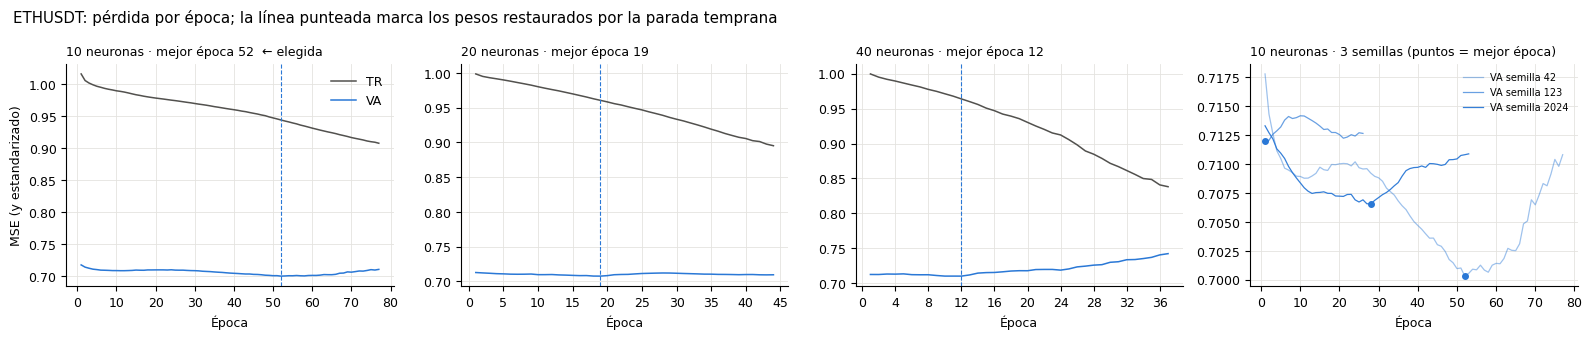

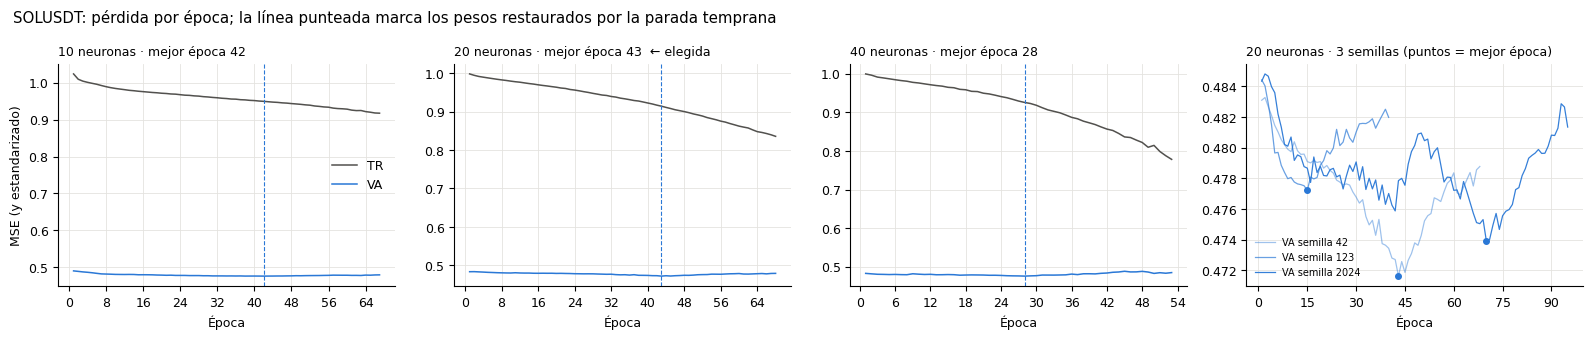

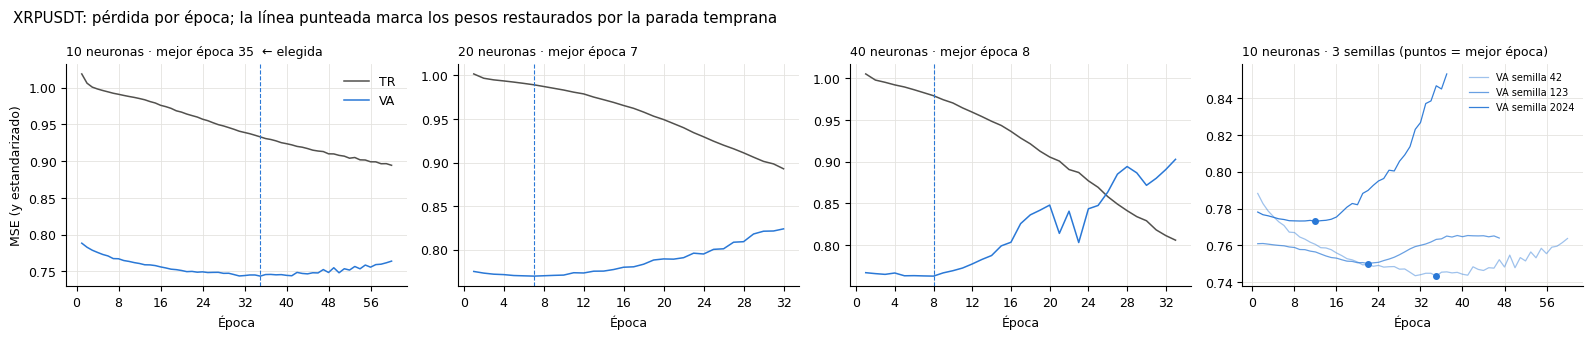

In [16]:
# === 7.2 Curvas de pérdida por época (búsqueda y semillas) ===
for sim in vigentes():
    a = ACT[sim]
    ncand = len(CONFIG['NEURONAS_CANDIDATAS'])
    fig, axes = plt.subplots(1, ncand + 1, figsize=(4.0 * (ncand + 1), 3.4), squeeze=False)
    for j, n_ in enumerate(CONFIG['NEURONAS_CANDIDATAS']):
        c = CORRIDAS[sim][f'{sim}_lstm_n{n_}_s{SEMILLA}']
        h, ax = c['hist'], axes[0, j]
        ep = np.arange(1, len(h) + 1)
        ax.plot(ep, h['loss'], color=TINTA2, lw=1.1, label='TR'); ax.plot(ep, h['val_loss'], color=AZUL, lw=1.1, label='VA')
        ax.axvline(c['info']['mejor_epoca'], color=AZUL, ls='--', lw=0.8)
        ax.set_title(f"{n_} neuronas · mejor época {c['info']['mejor_epoca']}" + ('  ← elegida' if n_ == a['mejor_n'] else ''), loc='left', fontsize=9)
        ax.set_xlabel('Época'); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        if j == 0:
            ax.set_ylabel('MSE (y estandarizado)'); ax.legend(frameon=False)
    ax = axes[0, -1]
    for k, i in enumerate(a['ids_final']):
        h, c = CORRIDAS[sim][i]['hist'], CORRIDAS[sim][i]
        ep = np.arange(1, len(h) + 1)
        ax.plot(ep, h['val_loss'], color=AZUL, lw=0.9, alpha=0.45 + 0.25 * k, label=f"VA semilla {c['semilla']}")
        ax.plot(c['info']['mejor_epoca'], h['val_loss'].iloc[c['info']['mejor_epoca'] - 1], 'o', color=AZUL, ms=4)
    ax.set_title(f"{a['mejor_n']} neuronas · 3 semillas (puntos = mejor época)", loc='left', fontsize=9)
    ax.set_xlabel('Época'); ax.legend(frameon=False, fontsize=7); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    fig.suptitle(f'{sim}: pérdida por época; la línea punteada marca los pesos restaurados por la parada temprana', x=0.01, ha='left')
    fig.tight_layout(); fig.savefig(DIRS_ACT[sim]['figuras'] / 'curvas_perdida_lstm.png', dpi=150, bbox_inches='tight'); plt.show()

## 8. Señal y simulación en VA: δ y estrategia C o D

- **C:** comprar, o mantener comprado, si $\hat y_t > \delta$; si no, efectivo.
- **D:** comprar, o mantener comprado, si $\hat y_t > \delta$ **y** $C_t > \text{SMA}_{20,t}$; si no, efectivo o cerrar la posición.
- δ se elige entre **hasta cinco valores positivos predefinidos**: los cuantiles 10, 25, 50, 75 y 90 % de las predicciones del ensamble **en TR**, registrados antes de simular VA. Se elige por mayor rendimiento neto en VA y, en empate, por menor drawdown; por separado para C y para D. Después se elige entre C y D con el mismo criterio.
- Simulación académica idéntica a BTC: señal al cierre de $t$, ejecución en la **apertura de $t+1$**, patrimonio valuado al cierre de $t+1$; solo largo o efectivo, sin apalancamiento; 0.10 % por compra y por venta; 100,000 USDT; liquidación al último cierre. Referencias: regresión lineal con su propio δ, comprar y mantener, y efectivo.
- Un umbral **no es una probabilidad de acierto**, y elegir el mejor de cinco valores en VA da una cifra optimista.

In [17]:
# === 8. Motor de simulación (mismas reglas que BTC) ===
def simular(precios, fechas_ejecucion, senales, costo=None, capital=None):
    '''senales[i] = 1 (comprar) o 0 (efectivo), emitida al cierre del día anterior a fechas_ejecucion[i].
    Se ejecuta en la apertura de fechas_ejecucion[i] y el patrimonio se valora a su cierre.'''
    costo = CONFIG['COSTO'] if costo is None else costo
    capital = CONFIG['CAPITAL_INICIAL'] if capital is None else capital
    fechas = pd.DatetimeIndex(pd.to_datetime(fechas_ejecucion))
    senales = np.asarray(senales).astype(int)
    if len(fechas) == 0:
        raise DatosVaciosError('No hay fechas para simular.')
    if len(fechas) != len(senales):
        raise DimensionError(f'{len(fechas)} fechas y {len(senales)} señales.')
    if fechas.duplicated().any() or not fechas.is_monotonic_increasing:
        raise FechaDuplicadaError('Las fechas de ejecución deben ser únicas y crecientes.')
    faltan = fechas.difference(precios.index)
    if len(faltan):
        raise DatosVaciosError(f'Sin precio de apertura/cierre para {len(faltan)} fechas, ej. {faltan[:3].date.tolist()}')
    if not set(np.unique(senales)) <= {0, 1}:
        raise ValorInvalidoError('Las señales deben ser 0 o 1.')
    p = precios.loc[fechas]
    efectivo, unidades, base, costos_tot = float(capital), 0.0, 0.0, 0.0
    filas, cerradas = [], []
    for f, s, o, c in zip(fechas, senales, p['open'].to_numpy(), p['close'].to_numpy()):
        cargo, accion = 0.0, 'mantener'
        if s == 1 and unidades == 0:
            monto = efectivo / (1 + costo)
            cargo = monto * costo
            unidades, base, efectivo, accion = monto / o, efectivo, 0.0, 'compra'
        elif s == 0 and unidades > 0:
            bruto = unidades * o
            cargo = bruto * costo
            efectivo, accion = bruto - cargo, 'venta'
            cerradas.append(efectivo - base)
            unidades = 0.0
        costos_tot += cargo
        filas.append({'fecha': f.date(), 'precio_ejecucion': o, 'senal': 'comprar' if s else 'efectivo', 'accion': accion,
                      'posicion_unidades': unidades, 'efectivo': efectivo, 'costo': cargo, 'precio_cierre': c,
                      'patrimonio': efectivo + unidades * c})
    if unidades > 0:                       # liquidación final al último cierre
        bruto = unidades * c
        cargo = bruto * costo
        efectivo = bruto - cargo
        cerradas.append(efectivo - base)
        costos_tot += cargo
        unidades = 0.0
        filas.append({'fecha': f.date(), 'precio_ejecucion': c, 'senal': 'liquidación', 'accion': 'venta final al cierre',
                      'posicion_unidades': 0.0, 'efectivo': efectivo, 'costo': cargo, 'precio_cierre': c, 'patrimonio': efectivo})
    sim_df = pd.DataFrame(filas)
    patrimonio = np.r_[capital, sim_df['patrimonio'].to_numpy()]
    dd = patrimonio / np.maximum.accumulate(patrimonio) - 1
    resumen = {'patrimonio_final': float(efectivo), 'rendimiento_neto': float(efectivo / capital - 1),
               'max_drawdown': float(dd.min()), 'operaciones_cerradas': len(cerradas),
               'transacciones': int((sim_df['costo'] > 0).sum()),
               'win_rate': (float(np.mean(np.array(cerradas) > 0)) if cerradas else np.nan),
               'costos_totales': float(costos_tot), 'dias_en_mercado_%': float(100 * senales.mean()),
               'primera_ejecucion': fechas[0].date(), 'ultima_valoracion': fechas[-1].date()}
    return resumen, sim_df

def candidatos(p_tr):
    q = np.quantile(p_tr, CONFIG['CUANTILES_UMBRAL'])
    pos_ = sorted({round(float(v), 6) for v in q if v > 0})
    return (pos_ or list(CONFIG['UMBRALES_RESPALDO']))[:5]

def elegir(df):
    df = df.assign(_r=df['rendimiento_neto'].round(8))
    return df.sort_values(['_r', 'max_drawdown'], ascending=[False, False]).iloc[0]

def curva(sim_df):
    s = sim_df.groupby('fecha')['patrimonio'].last()
    return pd.to_datetime(s.index), s.to_numpy()

RESUMEN_VA = []
for sim in vigentes():
    a, D = ACT[sim], DIRS_ACT[sim]
    a['precios'] = a['datos'].set_index('fecha')[['open', 'close']].astype(float)
    # Prueba de escritorio del motor: comprar el día 1 y vender el día 3 (verificable a mano)
    f3 = a['VA']['fecha_objetivo'].iloc[:3]
    r_p, _ = simular(a['precios'], f3, [1, 1, 0])
    o1, o3 = a['precios'].loc[f3.iloc[0], 'open'], a['precios'].loc[f3.iloc[2], 'open']
    esperado = CONFIG['CAPITAL_INICIAL'] / (1 + CONFIG['COSTO']) / o1 * o3 * (1 - CONFIG['COSTO'])
    if not np.isclose(r_p['patrimonio_final'], esperado) or r_p['operaciones_cerradas'] != 1:
        raise ValorInvalidoError(f'{sim}: el motor de simulación no reproduce el cálculo manual.')
    print(f"✔ {sim} prueba de escritorio: 100,000/(1+0.001)/{o1:,.4f}×{o3:,.4f}×(1−0.001) = {esperado:,.2f} = {r_p['patrimonio_final']:,.2f}")

    a['cand'] = {'final': candidatos(a['pred']['lstm']['TR']), 'lr': candidatos(a['pred']['regresion_lineal']['TR'])}
    json.dump({**a['cand'], 'origen': 'cuantiles de las predicciones en TR', 'cuantiles': CONFIG['CUANTILES_UMBRAL']},
              open(D['resultados'] / 'umbrales_candidatos.json', 'w'), indent=2)
    fechas_va = a['VA']['fecha_objetivo']
    filas_s, a['sims_va'] = [], {}
    for estrategia, pred, cand, con_filtro in (('C', a['pred']['lstm']['VA'], a['cand']['final'], False),
                                               ('D', a['pred']['lstm']['VA'], a['cand']['final'], True),
                                               ('LR', a['pred']['regresion_lineal']['VA'], a['cand']['lr'], False)):
        for d_ in cand:
            senal = (pred > d_) & (a['filtro']['VA'] if con_filtro else True)
            res, s_df = simular(a['precios'], fechas_va, senal.astype(int))
            a['sims_va'][(estrategia, d_)] = s_df
            filas_s.append({'estrategia': estrategia, 'delta': d_, **res})
    a['est_va'] = pd.DataFrame(filas_s)
    a['bh_va'], a['sim_bh_va'] = simular(a['precios'], fechas_va, np.ones(len(fechas_va), int))
    a['elec'] = {e: elegir(a['est_va'][a['est_va'].estrategia == e]) for e in ('C', 'D', 'LR')}
    a['estrategia_final'] = 'D' if (round(a['elec']['D']['rendimiento_neto'], 8), a['elec']['D']['max_drawdown']) > \
                                   (round(a['elec']['C']['rendimiento_neto'], 8), a['elec']['C']['max_drawdown']) else 'C'
    a['est_va'].to_csv(D['resultados'] / 'umbrales_C_D_LR_VA.csv', index=False)
    filas_r = [{'activo': sim, 'estrategia': e, 'delta': a['elec'][e]['delta'], 'elegida': e == a['estrategia_final'],
                **{k: a['elec'][e][k] for k in ('rendimiento_neto', 'max_drawdown', 'operaciones_cerradas', 'win_rate', 'dias_en_mercado_%', 'costos_totales')}}
               for e in ('C', 'D', 'LR')]
    filas_r += [{'activo': sim, 'estrategia': 'Comprar y mantener', 'delta': np.nan, 'elegida': False,
                 **{k: a['bh_va'][k] for k in ('rendimiento_neto', 'max_drawdown', 'operaciones_cerradas', 'win_rate', 'dias_en_mercado_%', 'costos_totales')}},
                {'activo': sim, 'estrategia': 'Efectivo', 'delta': np.nan, 'elegida': False, 'rendimiento_neto': 0.0, 'max_drawdown': 0.0,
                 'operaciones_cerradas': 0, 'win_rate': np.nan, 'dias_en_mercado_%': 0.0, 'costos_totales': 0.0}]
    pd.DataFrame(filas_r).to_csv(D['resultados'] / 'comparacion_estrategias_VA.csv', index=False)
    RESUMEN_VA += filas_r
    print(f"  {sim}: δ candidatos {[f'{x:.4%}' for x in a['cand']['final']]} → estrategia elegida con VA: {a['estrategia_final']} "
          f"(δ = {a['elec'][a['estrategia_final']]['delta']:.4%}); C {a['elec']['C']['rendimiento_neto']:+.2%} | "
          f"D {a['elec']['D']['rendimiento_neto']:+.2%} | comprar y mantener {a['bh_va']['rendimiento_neto']:+.2%}")
RESUMEN_VA = pd.DataFrame(RESUMEN_VA)
RESUMEN_VA.to_csv(DIRS_COMUN['resultados'] / 'comparacion_estrategias_VA.csv', index=False)
v = RESUMEN_VA.copy()
for c in ('rendimiento_neto', 'max_drawdown', 'win_rate'):
    v[c] = v[c].map(lambda x: '' if pd.isna(x) else f'{x:+.2%}')
v['delta'] = RESUMEN_VA['delta'].map(lambda x: '' if pd.isna(x) else f'{x:.4%}')
v

✔ ETHUSDT prueba de escritorio: 100,000/(1+0.001)/3,667.8500×3,560.1200×(1−0.001) = 96,868.93 = 96,868.93
  ETHUSDT: δ candidatos ['0.0486%', '0.1859%', '0.4315%', '0.6257%'] → estrategia elegida con VA: C (δ = 0.4315%); C +112.32% | D +110.12% | comprar y mantener +22.76%
✔ SOLUSDT prueba de escritorio: 100,000/(1+0.001)/188.4700×195.4900×(1−0.001) = 103,517.49 = 103,517.49
  SOLUSDT: δ candidatos ['0.1220%', '0.9800%', '2.2017%'] → estrategia elegida con VA: C (δ = 0.1220%); C +44.27% | D +18.94% | comprar y mantener -30.00%
✔ XRPUSDT prueba de escritorio: 100,000/(1+0.001)/0.5983×0.6001×(1−0.001) = 100,100.45 = 100,100.45
  XRPUSDT: δ candidatos ['0.1186%', '0.3708%', '0.7530%'] → estrategia elegida con VA: C (δ = 0.3708%); C +767.33% | D +442.52% | comprar y mantener +406.77%


,activo,estrategia,delta,elegida,rendimiento_neto,max_drawdown,operaciones_cerradas,win_rate,dias_en_mercado_%,costos_totales
0,ETHUSDT,C,0.4315%,True,+112.32%,-16.71%,34,+52.94%,19.594595,9123.303483
1,ETHUSDT,D,0.4315%,False,+110.12%,-11.43%,23,+52.17%,16.666667,6175.076248
2,ETHUSDT,LR,0.2470%,False,+36.32%,-42.97%,124,+58.06%,48.648649,23499.780691
3,ETHUSDT,Comprar y mantener,,False,+22.76%,-63.20%,1,+100.00%,100.000000,222.780886
4,ETHUSDT,Efectivo,,False,+0.00%,+0.00%,0,,0.000000,0.000000
5,SOLUSDT,C,0.1220%,True,+44.27%,-34.83%,32,+43.75%,41.159420,7303.331117
6,SOLUSDT,D,0.1220%,False,+18.94%,-21.02%,15,+40.00%,26.086957,2966.488982
7,SOLUSDT,LR,1.7650%,False,+0.16%,-4.80%,7,+57.14%,2.028986,1384.857173
8,SOLUSDT,Comprar y mantener,,False,-30.00%,-59.77%,1,+0.00%,100.000000,169.968515
9,SOLUSDT,Efectivo,,False,+0.00%,+0.00%,0,,0.000000,0.000000


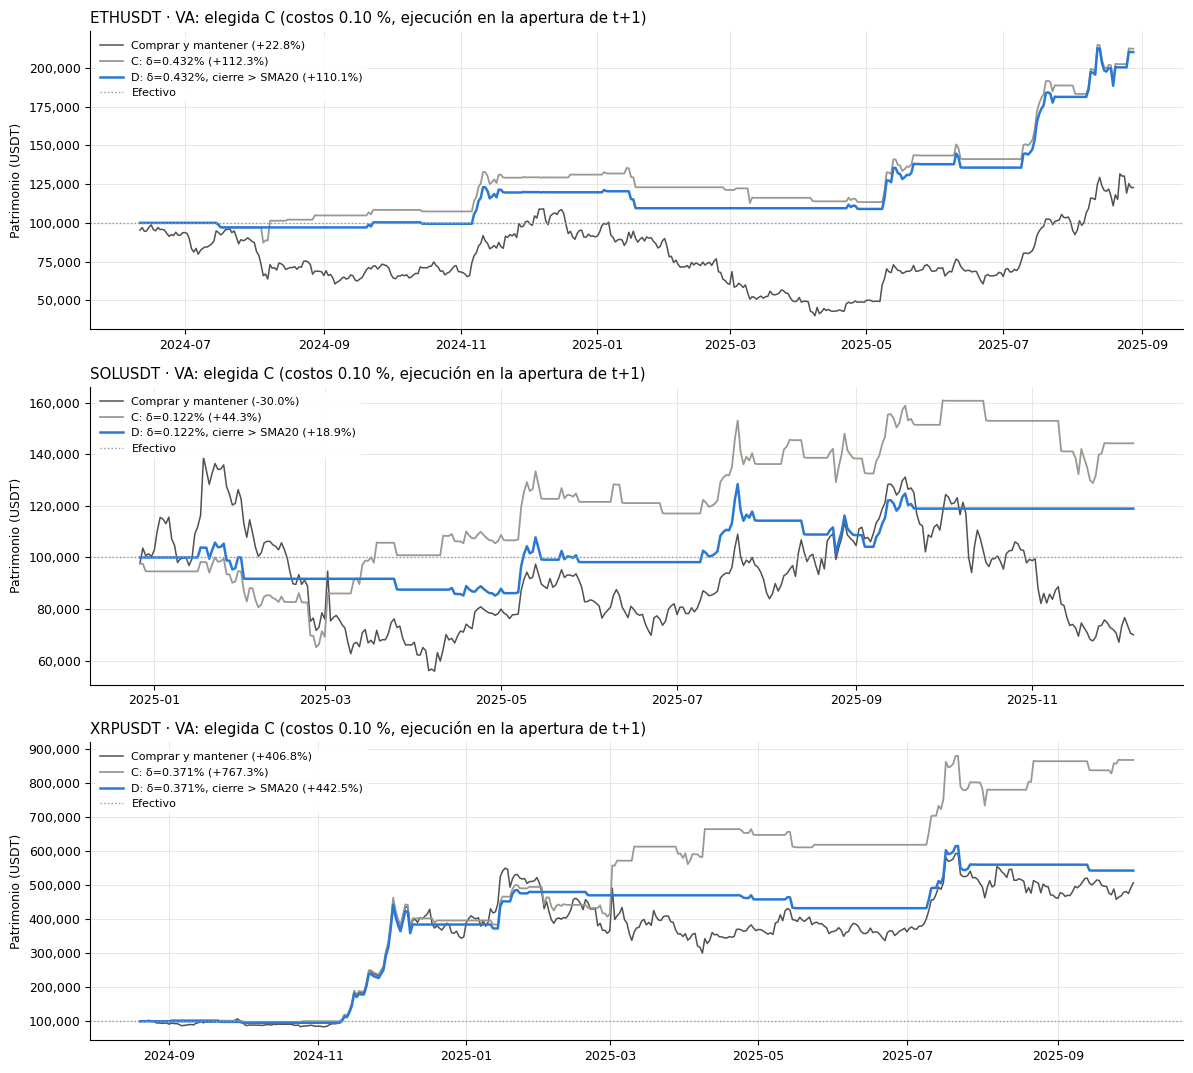

In [18]:
# === 8.1 Patrimonio en VA: C vs D vs comprar y mantener ===
vs = vigentes()
if vs:
    fig, axes = plt.subplots(len(vs), 1, figsize=(12, 3.6 * len(vs)), squeeze=False)
    for ax, sim in zip(axes[:, 0], vs):
        a = ACT[sim]
        for etiqueta, s_df, color, lw in ((f"Comprar y mantener ({a['bh_va']['rendimiento_neto']:+.1%})", a['sim_bh_va'], TINTA2, 1.1),
                                         (f"C: δ={a['elec']['C']['delta']:.3%} ({a['elec']['C']['rendimiento_neto']:+.1%})", a['sims_va'][('C', a['elec']['C']['delta'])], GRIS, 1.3),
                                         (f"D: δ={a['elec']['D']['delta']:.3%}, cierre > SMA20 ({a['elec']['D']['rendimiento_neto']:+.1%})", a['sims_va'][('D', a['elec']['D']['delta'])], AZUL, 1.8)):
            x, y = curva(s_df); ax.plot(x, y, color=color, lw=lw, label=etiqueta)
        ax.axhline(CONFIG['CAPITAL_INICIAL'], color=GRIS, ls=':', lw=1, label='Efectivo')
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v_, _: f'{v_:,.0f}')); ax.set_ylabel('Patrimonio (USDT)')
        ax.set_title(f"{sim} · VA: elegida {a['estrategia_final']} (costos 0.10 %, ejecución en la apertura de t+1)", loc='left')
        ax.legend(fontsize=8, loc='best', framealpha=0.85, edgecolor='none')
    fig.tight_layout()
    for sim in vs:
        fig.savefig(DIRS_ACT[sim]['figuras'] / 'patrimonio_VA_C_vs_D.png', dpi=150, bbox_inches='tight')
    plt.show()

## 9. Congelar la configuración final de cada activo (antes de mirar TE)

Para cada activo se fija aquí todo lo que se evalúa en TE: modelo, neuronas, semillas, checkpoints (con su SHA-256), escaladores, δ, filtro y estrategia, más la lista de versiones que se van a reportar. La configuración se guarda con una huella SHA-256. Si después de evaluar TE la configuración de un activo cambiara, el notebook **se detiene**. Así TE se usa **una sola vez** y nunca para elegir.

Las rutas se guardan relativas a la carpeta `DL_Finanzas`, igual que las de BTC, para que el backend del agente pueda cargarlas.

In [19]:
# === 9. Configuración final congelada ===
def rel(ruta):
    return str(Path(ruta).relative_to(BASE))

for sim in vigentes():
    a, D = ACT[sim], DIRS_ACT[sim]
    ckpts = [CORRIDAS[sim][i]['ckpt'] for i in a['ids_final']]
    rutas_esc = {'x': D['modelos'] / 'escalador_x_rezagos20.joblib', 'y': D['modelos'] / 'escalador_y.joblib'}
    e = a['estrategia_final']
    a['config_final'] = {
        'activo': sim, 'moneda_base': CONFIG['ACTIVOS'][sim], 'intervalo': INTV,
        'modelo_pronostico': 'lstm_A', 'neuronas': a['mejor_n'], 'semillas': CONFIG['SEMILLAS'], 'variables': FEATS,
        'contrato_entrada': 'ret_lag_0..ret_lag_19 (r_t … r_{t-19}); escalador_x; secuencia antiguo → reciente (1, 20, 1); salida inversa con escalador_y; promedio de 3 semillas',
        'checkpoints': [rel(c) for c in ckpts],
        'sha256_checkpoints': {rel(c): sha256_archivo(c) for c in ckpts},
        'escalador_x': rel(rutas_esc['x']), 'escalador_y': rel(rutas_esc['y']),
        'sha256_escaladores': {rel(r): sha256_archivo(r) for r in rutas_esc.values()},
        'estrategia': e, 'delta': float(a['elec'][e]['delta']),
        'filtro': 'cierre > SMA20' if e == 'D' else 'ninguno',
        'versiones_reportadas_en_TE': {'pronostico': ['cero', 'regresion_lineal', 'lstm_A'],
                                       'estrategias': {'C': float(a['elec']['C']['delta']), 'D': float(a['elec']['D']['delta']),
                                                       'LR': float(a['elec']['LR']['delta']), 'comprar_y_mantener': None, 'efectivo': None}},
        'criterios': 'neuronas por RMSE de VA (semilla 42); δ por rendimiento neto en VA (empate: drawdown); C/D por el mismo criterio',
        'costo': CONFIG['COSTO'], 'capital_inicial': CONFIG['CAPITAL_INICIAL'],
        'particiones': {r['conjunto']: {'n': int(r['n_ejemplos']), 'primer_objetivo': str(r['primer_objetivo']), 'ultimo_objetivo': str(r['ultimo_objetivo'])}
                        for _, r in a['particiones'].iterrows()},
        'sha256_crudo': a['meta']['sha256'],
    }
    huella = hashlib.sha256(json.dumps(a['config_final'], sort_keys=True, default=str).encode()).hexdigest()
    a['huella'] = huella
    ruta_cfg, ruta_log = D['resultados'] / 'configuracion_final_congelada.json', D['resultados'] / 'evaluacion_TE_registro.json'
    a['ruta_log_te'] = ruta_log
    if ruta_log.exists():
        a['log_te'] = json.load(open(ruta_log))
        if a['log_te']['sha256_configuracion'] != huella:
            registrar_evento(f'{sim} · evaluación TE', 'Configuración cambió después de ver TE',
                             f"antes {a['log_te']['sha256_configuracion'][:12]}, ahora {huella[:12]}",
                             'Detenido: TE ya se usó; no se puede reelegir. Restaurar la configuración o declarar contaminación.', 'pendiente')
            raise FugaInformacionError(f'{sim}: la configuración final cambió después de evaluar TE. TE ya no es independiente: '
                                       'restauren la configuración congelada (REENTRENAR=False y modelos de Drive) o declaren la contaminación.')
        print(f"{sim}: TE ya se evaluó el {a['log_te']['fecha_utc']} con esta misma configuración (SHA {huella[:12]}…): se reproduce, no se reelige.")
    else:
        a['log_te'] = None
        print(f'{sim}: configuración congelada (SHA-256 {huella[:16]}…). TE se evaluará por primera vez.')
    previa = json.load(open(ruta_cfg)) if ruta_cfg.exists() else {}
    if previa.get('sha256') != huella:          # no se reescribe si ya está congelada igual (conserva su fecha)
        json.dump({**a['config_final'], 'sha256': huella, 'congelado_utc': datetime.now(timezone.utc).isoformat(timespec='seconds')},
                  open(ruta_cfg, 'w'), indent=2, ensure_ascii=False)
    CONGELADO[sim] = True
display(pd.DataFrame({sim: {'neuronas': ACT[sim]['config_final']['neuronas'], 'estrategia': ACT[sim]['config_final']['estrategia'],
                            'delta': f"{ACT[sim]['config_final']['delta']:.4%}", 'filtro': ACT[sim]['config_final']['filtro'],
                            'sha256': ACT[sim]['huella'][:16] + '…'} for sim in vigentes()}))

ETHUSDT: configuración congelada (SHA-256 c49885c80da96409…). TE se evaluará por primera vez.
SOLUSDT: configuración congelada (SHA-256 6d5cea915fec4536…). TE se evaluará por primera vez.
XRPUSDT: configuración congelada (SHA-256 fcef205fa3397c36…). TE se evaluará por primera vez.


,ETHUSDT,SOLUSDT,XRPUSDT
neuronas,10,20,10
estrategia,C,C,C
delta,0.4315%,0.1220%,0.3708%
filtro,ninguno,ninguno,ninguno
sha256,c49885c80da96409…,6d5cea915fec4536…,fcef205fa3397c36…


## 10. Evaluación de TE (una sola vez por activo) y resultados finales

In [20]:
# === 10. Predicciones de TE, métricas en TR, VA y TE y simulación ===
RES_FINAL, TRADING_TE = [], []
for sim in vigentes():
    a, D = ACT[sim], DIRS_ACT[sim]
    a['pred']['lstm']['TE'] = a['a_rendimiento'](predecir(sim, a['modelos_final'], a['seq']['TE'], 'TE'))
    a['pred']['regresion_lineal']['TE'] = predecir(sim, a['lr'], a['Xe']['TE'], 'TE')
    a['pred']['cero']['TE'] = np.zeros(len(a['Y']['TE']))
    filas_res = [{'activo': sim, 'modelo': nombre, 'conjunto': c, **metricas(a['Y'][c], a['pred'][clave][c])}
                 for nombre, clave in (('cero', 'cero'), ('regresion_lineal', 'regresion_lineal'), (f"lstm_A_n{a['mejor_n']}_ensamble3", 'lstm'))
                 for c in ('TR', 'VA', 'TE')]
    pd.DataFrame(filas_res).to_csv(D['resultados'] / 'resultados_finales_TR_VA_TE.csv', index=False)
    RES_FINAL += filas_res
    registrar_experimentos(sim, [{'id': f"{sim}_final_{r['modelo']}", 'modelo': r['modelo'], 'tipo': 'evaluacion_final', 'conjunto': r['conjunto'],
                                  **{k: r[k] for k in ('MAE', 'RMSE', 'prec_direccional', 'n')}} for r in filas_res])
    cf, e = a['config_final'], a['estrategia_final']
    senal_te = (a['pred']['lstm']['TE'] > cf['delta']) & (a['filtro']['TE'] if e == 'D' else True)
    pd.DataFrame({'fecha_emision': a['TE']['fecha_emision'].dt.date, 'fecha_objetivo': a['TE']['fecha_objetivo'].dt.date,
                  'rendimiento_real': a['Y']['TE'], 'rendimiento_estimado': a['pred']['lstm']['TE'], 'error': a['pred']['lstm']['TE'] - a['Y']['TE'],
                  'senal': np.where(senal_te, 'comprar', 'efectivo'), 'estimado_regresion_lineal': a['pred']['regresion_lineal']['TE'],
                  'cierre_sobre_SMA20': a['filtro']['TE']}).to_csv(D['resultados'] / 'predicciones_TE.csv', index=False)
    fechas_te = a['TE']['fecha_objetivo']
    a['sims_te'], est_te = {}, []
    for nombre, senal in [(f"C (δ = {a['elec']['C']['delta']:.4%})", a['pred']['lstm']['TE'] > a['elec']['C']['delta']),
                          (f"D (δ = {a['elec']['D']['delta']:.4%}, cierre > SMA20)", (a['pred']['lstm']['TE'] > a['elec']['D']['delta']) & a['filtro']['TE']),
                          (f"Regresión lineal (δ = {a['elec']['LR']['delta']:.4%})", a['pred']['regresion_lineal']['TE'] > a['elec']['LR']['delta']),
                          ('Comprar y mantener', np.ones(len(fechas_te), bool)), ('Efectivo', np.zeros(len(fechas_te), bool))]:
        res, s_df = simular(a['precios'], fechas_te, senal.astype(int))
        res0, _ = simular(a['precios'], fechas_te, senal.astype(int), costo=0.0)
        a['sims_te'][nombre] = s_df
        est_te.append({'activo': sim, 'estrategia': nombre, 'final': nombre.startswith(e + ' '), **res, 'rendimiento_neto_sin_costos': res0['rendimiento_neto']})
    a['est_te'] = pd.DataFrame(est_te)
    a['est_te'].drop(columns=['activo']).to_csv(D['resultados'] / 'resultados_trading_TE.csv', index=False)
    TRADING_TE += est_te
    a['nombre_final'] = a['est_te'].loc[a['est_te']['final'], 'estrategia'].iloc[0]
    a['sims_te'][a['nombre_final']][['fecha', 'precio_ejecucion', 'senal', 'accion', 'posicion_unidades', 'efectivo', 'costo', 'patrimonio']].rename(
        columns={'posicion_unidades': 'posicion', 'costo': 'costos'}).to_csv(D['resultados'] / 'simulacion.csv', index=False)
    fin = a['est_te'][a['est_te']['final']].iloc[0]
    rmse_te = [r for r in filas_res if r['modelo'].startswith('lstm') and r['conjunto'] == 'TE'][0]['RMSE']
    registro = {'fecha_utc': (a['log_te'] or {}).get('fecha_utc', datetime.now(timezone.utc).isoformat(timespec='seconds')),
                'sha256_configuracion': a['huella'], 'estrategia_final': a['nombre_final'],
                'rendimiento_neto_TE': float(fin['rendimiento_neto']), 'RMSE_TE_modelo_final': float(rmse_te)}
    if a['log_te'] is not None:
        if not (np.isclose(a['log_te']['rendimiento_neto_TE'], registro['rendimiento_neto_TE'], rtol=1e-6)
                and np.isclose(a['log_te']['RMSE_TE_modelo_final'], registro['RMSE_TE_modelo_final'], rtol=1e-6)):
            registrar_evento(f'{sim} · evaluación TE', 'Resultado de TE distinto al registrado', 'la ejecución no reprodujo los modelos',
                             'revisar que REENTRENAR sea False y que los modelos de Drive no hayan cambiado', 'pendiente')
            raise ValorInvalidoError(f'{sim}: la reevaluación de TE no reproduce el resultado registrado.')
        print(f'✔ {sim}: resultado de TE idéntico al de la primera evaluación.')
    else:
        json.dump(registro, open(a['ruta_log_te'], 'w'), indent=2, ensure_ascii=False)
        print(f'{sim}: TE evaluado por primera vez y registrado.')
    bh = a['est_te'][a['est_te'].estrategia == 'Comprar y mantener'].iloc[0]
    lr_ = a['est_te'][a['est_te'].estrategia.str.startswith('Regresión')].iloc[0]
    print(f"  {sim} · sistema final {a['nombre_final']}: {fin['rendimiento_neto']:+.2%} | drawdown {fin['max_drawdown']:.2%} | "
          f"{int(fin['operaciones_cerradas'])} operaciones | comprar y mantener {bh['rendimiento_neto']:+.2%} | regresión lineal {lr_['rendimiento_neto']:+.2%} | "
          f"meta +{CONFIG['META_RENDIMIENTO_TE']:.0%}: {'alcanzada' if fin['rendimiento_neto'] >= CONFIG['META_RENDIMIENTO_TE'] else 'no alcanzada'}")
RES_FINAL, TRADING_TE = pd.DataFrame(RES_FINAL), pd.DataFrame(TRADING_TE)
RES_FINAL.to_csv(DIRS_COMUN['resultados'] / 'resultados_finales_TR_VA_TE.csv', index=False)
TRADING_TE.to_csv(DIRS_COMUN['resultados'] / 'resultados_trading_TE.csv', index=False)
print('\nRMSE por activo, modelo y conjunto:')
display(RES_FINAL.pivot_table(index=['activo', 'modelo'], columns='conjunto', values='RMSE', sort=False)[['TR', 'VA', 'TE']].round(6))
v = TRADING_TE.drop(columns=['final']).copy()
for c in ('rendimiento_neto', 'max_drawdown', 'win_rate', 'rendimiento_neto_sin_costos'):
    v[c] = v[c].map(lambda x: '' if pd.isna(x) else f'{x:+.2%}')
v[['activo', 'estrategia', 'rendimiento_neto', 'max_drawdown', 'operaciones_cerradas', 'win_rate', 'costos_totales', 'dias_en_mercado_%', 'rendimiento_neto_sin_costos']]

ETHUSDT: TE evaluado por primera vez y registrado.
  ETHUSDT · sistema final C (δ = 0.4315%): -38.75% | drawdown -43.74% | 31 operaciones | comprar y mantener -59.63% | regresión lineal -46.77% | meta +20%: no alcanzada
SOLUSDT: TE evaluado por primera vez y registrado.
  SOLUSDT · sistema final C (δ = 0.1220%): +6.74% | drawdown -36.62% | 22 operaciones | comprar y mantener -43.23% | regresión lineal +0.00% | meta +20%: no alcanzada
XRPUSDT: TE evaluado por primera vez y registrado.
  XRPUSDT · sistema final C (δ = 0.3708%): -15.26% | drawdown -30.16% | 22 operaciones | comprar y mantener -67.69% | regresión lineal -37.90% | meta +20%: no alcanzada

RMSE por activo, modelo y conjunto:


conjunto                            TR        VA        TE
activo  modelo                                            
ETHUSDT cero                  0.045610  0.038442  0.032170
        regresion_lineal      0.045007  0.038514  0.032878
        lstm_A_n10_ensamble3  0.044665  0.038172  0.032210
SOLUSDT cero                  0.066783  0.046140  0.032141
        regresion_lineal      0.065783  0.046882  0.032905
        lstm_A_n20_ensamble3  0.061959  0.045624  0.032247
XRPUSDT cero                  0.055867  0.049323  0.034588
        regresion_lineal      0.055532  0.049048  0.034750
        lstm_A_n10_ensamble3  0.054554  0.048292  0.034143

,activo,estrategia,rendimiento_neto,max_drawdown,operaciones_cerradas,win_rate,costos_totales,dias_en_mercado_%,rendimiento_neto_sin_costos
0,ETHUSDT,C (δ = 0.4315%),-38.75%,-43.74%,31,+25.81%,5098.764822,13.901345,-34.84%
1,ETHUSDT,"D (δ = 0.4315%, cierre > SMA20)",-29.24%,-30.02%,18,+22.22%,2993.043171,9.641256,-26.64%
2,ETHUSDT,Regresión lineal (δ = 0.2470%),-46.77%,-57.92%,127,+51.18%,18530.468069,48.878924,-31.38%
3,ETHUSDT,Comprar y mantener,-59.63%,-66.73%,1,+0.00%,140.310395,100.000000,-59.55%
4,ETHUSDT,Efectivo,+0.00%,+0.00%,0,,0.000000,0.000000,+0.00%
5,SOLUSDT,C (δ = 0.1220%),+6.74%,-36.62%,22,+36.36%,3611.457647,30.346821,+11.54%
6,SOLUSDT,"D (δ = 0.1220%, cierre > SMA20)",+13.31%,-19.77%,16,+37.50%,2944.261388,21.387283,+17.00%
7,SOLUSDT,Regresión lineal (δ = 1.7650%),+0.00%,+0.00%,0,,0.000000,0.000000,+0.00%
8,SOLUSDT,Comprar y mantener,-43.23%,-57.59%,1,+0.00%,156.723525,100.000000,-43.12%
9,SOLUSDT,Efectivo,+0.00%,+0.00%,0,,0.000000,0.000000,+0.00%


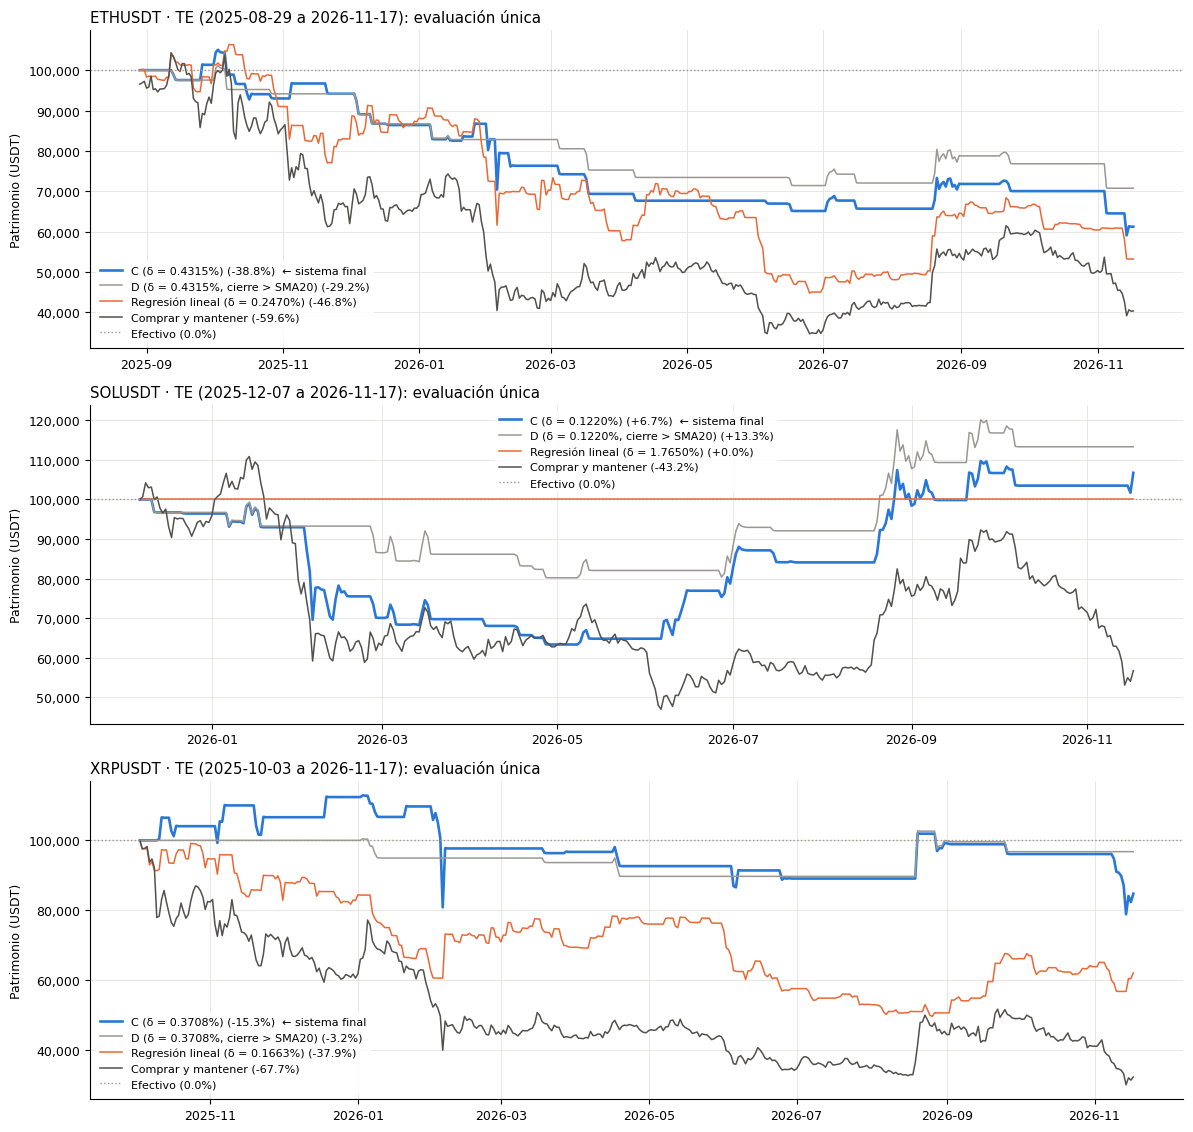

In [21]:
# === 10.1 Patrimonio en TE ===
vs = vigentes()
if vs:
    fig, axes = plt.subplots(len(vs), 1, figsize=(12, 3.8 * len(vs)), squeeze=False)
    for ax, sim in zip(axes[:, 0], vs):
        a = ACT[sim]
        for nombre, s_df in a['sims_te'].items():
            if nombre == 'Efectivo':
                continue
            x, y = curva(s_df)
            r = a['est_te'][a['est_te'].estrategia == nombre]['rendimiento_neto'].iloc[0]
            final = nombre == a['nombre_final']
            color = AZUL if final else (TINTA2 if nombre == 'Comprar y mantener' else NARANJA if nombre.startswith('Regresión') else GRIS)
            ax.plot(x, y, color=color, lw=1.9 if final else 1.1, label=f'{nombre} ({r:+.1%})' + ('  ← sistema final' if final else ''))
        ax.axhline(CONFIG['CAPITAL_INICIAL'], color=GRIS, ls=':', lw=1, label='Efectivo (0.0%)')
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v_, _: f'{v_:,.0f}')); ax.set_ylabel('Patrimonio (USDT)')
        ax.set_title(f"{sim} · TE ({a['TE'].fecha_objetivo.min().date()} a {a['TE'].fecha_objetivo.max().date()}): evaluación única", loc='left')
        ax.legend(fontsize=8, loc='best', framealpha=0.85, edgecolor='none')
    fig.tight_layout()
    for sim in vs:
        fig.savefig(DIRS_ACT[sim]['figuras'] / 'patrimonio_TE.png', dpi=150, bbox_inches='tight')
    plt.show()

## 11. Cargar el modelo final y los escaladores desde Drive y repetir predicciones

Se cargan los checkpoints y los escaladores **desde los archivos congelados** (como lo hará el backend del agente) y se repiten las primeras 10 predicciones de TE. También se verifica que los archivos no cambiaron respecto a sus huellas.

In [22]:
# === 11. Recarga y repetición ===
for sim in vigentes():
    a, cf = ACT[sim], ACT[sim]['config_final']
    for r, h in {**cf['sha256_checkpoints'], **cf['sha256_escaladores']}.items():
        if sha256_archivo(BASE / r) != h:
            raise ValorInvalidoError(f'{sim}: {r} cambió después de congelar la configuración.')
    mods = [keras.models.load_model(BASE / c) for c in cf['checkpoints']]
    ex, ey = joblib.load(BASE / cf['escalador_x']), joblib.load(BASE / cf['escalador_y'])
    xr = a_secuencia(ex.transform(a['TE'][FEATS].to_numpy(float)[:10]))
    rep = ey.inverse_transform(predecir(sim, mods, xr, 'TE').reshape(-1, 1)).ravel()
    if not np.allclose(rep, a['pred']['lstm']['TE'][:10], rtol=1e-4, atol=1e-7):
        raise ValorInvalidoError(f'{sim}: el modelo cargado desde Drive no repite las predicciones.')
    print(f'✔ {sim}: checkpoints y escaladores con sus SHA-256 congelados; el modelo cargado repite las predicciones de TE.')

✔ ETHUSDT: checkpoints y escaladores con sus SHA-256 congelados; el modelo cargado repite las predicciones de TE.
✔ SOLUSDT: checkpoints y escaladores con sus SHA-256 congelados; el modelo cargado repite las predicciones de TE.
✔ XRPUSDT: checkpoints y escaladores con sus SHA-256 congelados; el modelo cargado repite las predicciones de TE.


## 12. Pronóstico del siguiente periodo no observado

Se descarga la historia **reciente** de MEXC de cada activo, **sin modificar** su crudo ni TR, VA y TE. Se aplican la misma auditoría y la misma tabla de indicadores, se comprueba que los precios coinciden con el archivo congelado en las fechas comunes y se pronostica el día siguiente al **último cierre completo**. El valor real queda vacío hasta observarse. Si la descarga falla, se usa el último cierre del archivo congelado y se registra en la bitácora.

In [23]:
# === 12. Pronóstico futuro ===
FUTURO = []
for sim in vigentes():
    a, D, cf = ACT[sim], DIRS_ACT[sim], ACT[sim]['config_final']
    fuente, dia_f = 'archivo congelado', a['DIA']
    if CONFIG['DESCARGAR_DATOS_RECIENTES']:
        try:
            ini = (pd.Timestamp.now(tz='UTC').normalize() - pd.Timedelta(days=CONFIG['DIAS_RECIENTES'])).strftime('%Y-%m-%d')
            rec_raw, info_rec = descargar_klines_mexc(sim, INTV, ini)
            sello = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
            ruta_rec = D['crudos'] / f'{sim}_{INTV}_mexc_recientes_{sello}.csv'
            rec_raw.to_csv(ruta_rec, index=False)
            rec, _, _, _ = auditar(rec_raw, {'descarga_ms': info_rec['descarga_ms']}, 60, CONFIG['HUECO_MAX_DIAS'])
            comun = rec.merge(a['datos'][['fecha', 'close']], on='fecha', suffixes=('', '_congelado'))
            if len(comun) and not np.allclose(comun['close'], comun['close_congelado'], rtol=1e-9):
                registrar_evento(f'{sim} · pronóstico futuro', 'Precios recientes distintos al archivo congelado', f'{len(comun)} fechas comunes',
                                 'Se usa el archivo congelado para el pronóstico', 'revisar fuente')
            else:
                dia_f = tabla_diaria(rec[['fecha', 'open', 'high', 'low', 'close']])
                fuente = f'descarga reciente de MEXC ({ruta_rec.name}, SHA-256 {sha256_archivo(ruta_rec)[:12]}…); coincide con el crudo congelado en {len(comun)} fechas comunes'
        except (DescargaError, DatosVaciosError, DimensionError, FechaDuplicadaError, ValorInvalidoError) as e:
            registrar_evento(f'{sim} · pronóstico futuro', type(e).__name__, str(e)[:150], 'Se usa el último cierre del archivo congelado', 'pronóstico generado')
    fecha_corte = dia_f['close'].last_valid_index()
    pc = dia_f.index.get_loc(fecha_corte)
    ultimos = dia_f.iloc[pc - N + 1: pc + 1]
    if len(ultimos) < N or not np.isfinite(ultimos[['ret'] + IND].to_numpy()).all():
        registrar_evento(f'{sim} · pronóstico futuro', 'DatosVaciosError', f'No hay {N} días completos hasta {fecha_corte.date()}',
                         'No se emite pronóstico para este activo', 'sin pronóstico')
        continue
    lags_f = ultimos['ret'].to_numpy()[::-1].reshape(1, -1)               # ret_lag_0 = r del día de corte
    CONJUNTOS_PREDICHOS[sim].add('FUTURO')
    salida = np.mean([np.asarray(m.predict(a_secuencia(a['esc_x'].transform(lags_f)), verbose=0)).ravel() for m in a['modelos_final']], axis=0)
    y_f = float(a['a_rendimiento'](salida)[0])
    sobre_sma = bool(ultimos['dist_sma20'].iloc[-1] > 0)
    senal_f = (y_f > cf['delta']) and (sobre_sma if cf['estrategia'] == 'D' else True)
    fila = {'activo': sim, 'fecha_corte': fecha_corte.date(), 'proximo_periodo': (fecha_corte + pd.Timedelta(days=1)).date(),
            'rendimiento_estimado': y_f, 'senal': 'comprar' if senal_f else 'efectivo', 'valor_real': '',
            'modelo': f"lstm_A_n{cf['neuronas']}_ensamble3", 'estrategia': cf['estrategia'], 'delta': cf['delta'],
            'cierre_sobre_SMA20': sobre_sma, 'cierre_en_corte': float(ultimos['close'].iloc[-1]), 'fuente_datos': fuente,
            'generado_utc': datetime.now(timezone.utc).isoformat(timespec='seconds')}
    pd.DataFrame([fila]).drop(columns=['activo']).to_csv(D['resultados'] / 'prediccion_futura.csv', index=False)
    FUTURO.append(fila)
    print(f"{sim}: último cierre completo {fecha_corte.date()} ({fila['cierre_en_corte']:,.4f} USDT) → pronóstico para {fila['proximo_periodo']}: "
          f"{y_f:+.4%} → señal {fila['senal'].upper()}  [{fuente[:60]}…]")
FUTURO = pd.DataFrame(FUTURO)
FUTURO.to_csv(DIRS_COMUN['resultados'] / 'prediccion_futura.csv', index=False)
print('Son predicciones futuras, todavía no evaluables: su valor real queda vacío.')

  2026-06-21 → 2026-11-18: 151 velas
ETHUSDT: último cierre completo 2026-11-17 (1,824.9700 USDT) → pronóstico para 2026-11-18: +0.0718% → señal EFECTIVO  [descarga reciente de MEXC (ETHUSDT_1d_mexc_recientes_2026111…]
  2026-06-21 → 2026-11-18: 151 velas
SOLUSDT: último cierre completo 2026-11-17 (75.1900 USDT) → pronóstico para 2026-11-18: +1.0945% → señal COMPRAR  [descarga reciente de MEXC (SOLUSDT_1d_mexc_recientes_2026111…]
  2026-06-21 → 2026-11-18: 151 velas
XRPUSDT: último cierre completo 2026-11-17 (0.9837 USDT) → pronóstico para 2026-11-18: +0.1177% → señal EFECTIVO  [descarga reciente de MEXC (XRPUSDT_1d_mexc_recientes_2026111…]
Son predicciones futuras, todavía no evaluables: su valor real queda vacío.


## 13. Resumen comparativo con BTC y paquete para el agente

La tabla reúne, por activo, la selección con VA y la evaluación única de TE. BTC se lee de sus propios archivos (`DL_Finanzas/resultados/`), sin recalcular nada. **Los TE no son comparables entre sí como una carrera:** cada activo tiene su propio periodo de prueba.

`paquete_agente.json` es el contrato que leerá el backend multi-activo (v1.3): rutas de checkpoints y escaladores, δ, estrategia, filtro y huella de cada activo.

In [24]:
# === 13. Resumen y paquete para el agente ===
filas = []
btc_tr, btc_cfg, btc_res = BASE / 'resultados' / 'resultados_trading_TE.csv', BASE / 'resultados' / 'configuracion_final_congelada.json', BASE / 'resultados' / 'resultados_finales_TR_VA_TE.csv'
if btc_tr.exists() and btc_cfg.exists() and btc_res.exists():
    t, cfg_b, rr = pd.read_csv(btc_tr), json.load(open(btc_cfg)), pd.read_csv(btc_res)
    fin_b = t[t['final'].astype(str) == 'True'].iloc[0]
    bh_b = t[t.estrategia == 'Comprar y mantener'].iloc[0]
    p_b = pd.read_csv(BASE / 'resultados' / 'particiones.csv').set_index('conjunto')
    filas.append({'activo': 'BTCUSDT (referencia)', 'neuronas': cfg_b['neuronas'], 'estrategia': cfg_b['estrategia'], 'delta': cfg_b['delta'],
                  'TE_desde': p_b.loc['TE', 'primer_objetivo'], 'TE_hasta': p_b.loc['TE', 'ultimo_objetivo'], 'n_TE': int(p_b.loc['TE', 'n_ejemplos']),
                  'RMSE_TE_cero': rr[(rr.modelo == 'cero') & (rr.conjunto == 'TE')]['RMSE'].astype(float).iloc[0],
                  'RMSE_TE_lstm': rr[(rr.modelo == cfg_b['modelo_pronostico']) & (rr.conjunto == 'TE')]['RMSE'].astype(float).iloc[0],
                  'rend_TE_sistema': fin_b['rendimiento_neto'], 'drawdown_TE_sistema': fin_b['max_drawdown'],
                  'rend_TE_comprar_y_mantener': bh_b['rendimiento_neto'], 'sha256': cfg_b['sha256'][:16]})
for sim in vigentes():
    a = ACT[sim]
    fin = a['est_te'][a['est_te']['final']].iloc[0]
    bh = a['est_te'][a['est_te'].estrategia == 'Comprar y mantener'].iloc[0]
    rr = RES_FINAL[(RES_FINAL.activo == sim) & (RES_FINAL.conjunto == 'TE')].set_index('modelo')['RMSE']
    filas.append({'activo': sim, 'neuronas': a['mejor_n'], 'estrategia': a['estrategia_final'], 'delta': a['config_final']['delta'],
                  'TE_desde': a['TE'].fecha_objetivo.min().date(), 'TE_hasta': a['TE'].fecha_objetivo.max().date(), 'n_TE': len(a['TE']),
                  'RMSE_TE_cero': rr['cero'], 'RMSE_TE_lstm': rr[f"lstm_A_n{a['mejor_n']}_ensamble3"],
                  'rend_TE_sistema': fin['rendimiento_neto'], 'drawdown_TE_sistema': fin['max_drawdown'],
                  'rend_TE_comprar_y_mantener': bh['rendimiento_neto'], 'sha256': a['huella'][:16]})
RESUMEN = pd.DataFrame(filas)
RESUMEN.to_csv(DIRS_COMUN['resultados'] / 'resumen_activos.csv', index=False)

PAQUETE = {'generado_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'), 'raiz': 'carpeta DL_Finanzas (rutas relativas)',
           'nota': 'Cada activo tiene su propio modelo, escaladores, δ y estrategia, elegidos con su VA y evaluados una vez en su TE. No se usan pesos ni escalas de BTC.',
           'activos': {sim: {'config_congelada': rel(DIRS_ACT[sim]['resultados'] / 'configuracion_final_congelada.json'),
                             'sha256_config': ACT[sim]['huella'], 'checkpoints': ACT[sim]['config_final']['checkpoints'],
                             'escalador_x': ACT[sim]['config_final']['escalador_x'], 'escalador_y': ACT[sim]['config_final']['escalador_y'],
                             'neuronas': ACT[sim]['mejor_n'], 'estrategia': ACT[sim]['estrategia_final'], 'delta': ACT[sim]['config_final']['delta'],
                             'filtro': ACT[sim]['config_final']['filtro'], 'ultima_fecha_datos': str(ACT[sim]['datos'].fecha.max().date()),
                             'rendimiento_neto_TE': float(ACT[sim]['est_te'][ACT[sim]['est_te']['final']]['rendimiento_neto'].iloc[0])}
                       for sim in vigentes()},
           'excluidos': EXCLUIDOS}
json.dump(PAQUETE, open(BASE_EXTRA / 'paquete_agente.json', 'w'), indent=2, ensure_ascii=False)
v = RESUMEN.copy()
for c in ('rend_TE_sistema', 'drawdown_TE_sistema', 'rend_TE_comprar_y_mantener'):
    v[c] = v[c].map(lambda x: f'{float(x):+.2%}')
v['delta'] = RESUMEN['delta'].map(lambda x: f'{float(x):.4%}')
print(f"Paquete para el agente: {rel(BASE_EXTRA / 'paquete_agente.json')}")
v

Paquete para el agente: activos_extra/paquete_agente.json


,activo,neuronas,estrategia,delta,TE_desde,TE_hasta,n_TE,RMSE_TE_cero,RMSE_TE_lstm,rend_TE_sistema,drawdown_TE_sistema,rend_TE_comprar_y_mantener,sha256
0,BTCUSDT (referencia),20,D,0.0866%,2025-08-18,2026-11-04,444,0.022297,0.022319,-3.25%,-25.39%,-31.57%,97f125d051548502
1,ETHUSDT,10,C,0.4315%,2025-08-29,2026-11-17,446,0.032170,0.032210,-38.75%,-43.74%,-59.63%,c49885c80da96409
2,SOLUSDT,20,C,0.1220%,2025-12-07,2026-11-17,346,0.032141,0.032247,+6.74%,-36.62%,-43.23%,6d5cea915fec4536
3,XRPUSDT,10,C,0.3708%,2025-10-03,2026-11-17,411,0.034588,0.034143,-15.26%,-30.16%,-67.69%,fcef205fa3397c36


## 14. Ejecución limpia, controles finales y seguimiento

In [25]:
# === 14. Lista de comprobación y respuesta basada en la evidencia ===
controles, lineas = {}, []
for sim in ACTIVOS:
    if sim in EXCLUIDOS:
        controles[sim] = {'estado': f'excluido — {EXCLUIDOS[sim]}'}
        lineas.append(f'{sim}: excluido ({EXCLUIDOS[sim]}).')
        continue
    a, D = ACT[sim], DIRS_ACT[sim]
    infos = [CORRIDAS[sim][i]['info'] for i in CORRIDAS[sim]]
    controles[sim] = {
        'T4 verificada y entrenamientos en GPU': bool(EVIDENCIA_T4.get('T4_OK')) and all('GPU' in i['dispositivo_pesos'].upper() for i in infos),
        'Crudo con SHA-256 verificado': sha256_archivo(a['arch_crudo']) == a['meta']['sha256'],
        'Observaciones válidas ≥ 1,500': len(a['datos']) >= CONFIG['MIN_OBS'],
        'Último objetivo TR < primero VA < primero TE': bool(a['TR'].fecha_objetivo.max() < a['VA'].fecha_objetivo.min() < a['TE'].fecha_objetivo.min()),
        'Escaladores ajustados solo con TR': int(a['esc_x'].n_samples_seen_) == len(a['TR']) == int(a['esc_y'].n_samples_seen_),
        'Filtro SMA20 sin información futura (prueba de alteración)': True,
        'Configuración congelada antes de TE (SHA-256)': (D['resultados'] / 'configuracion_final_congelada.json').exists(),
        'TE evaluado una sola vez (registro)': a['ruta_log_te'].exists(),
        'Pronóstico futuro con valor real vacío': (not len(FUTURO)) or bool((FUTURO[FUTURO.activo == sim]['valor_real'] == '').all()),
        'Conjuntos sobre los que se predijo': ', '.join(sorted(CONJUNTOS_PREDICHOS[sim])),
    }
    d_, fin = a['diagnostico'], a['est_te'][a['est_te']['final']].iloc[0]
    bh = a['est_te'][a['est_te'].estrategia == 'Comprar y mantener'].iloc[0]
    c_d = a['elec']['D']['rendimiento_neto'] - a['elec']['C']['rendimiento_neto']
    lineas += [
        f"{sim} — pronóstico (VA): LSTM {a['mejor_n']} neuronas, ensamble RMSE {d_['RMSE_VA_ensamble']:.6f} frente a cero {d_['RMSE_VA_cero']:.6f} "
        f"y regresión lineal {d_['RMSE_VA_regresion_lineal']:.6f}; ¿mejora a la mejor referencia más que el ruido entre semillas? "
        f"{'sí' if d_['supera_mejor_referencia_mas_que_ruido'] else 'no'} → selección general: {d_['seleccion_general']}. "
        f"Predicciones {'casi constantes' if d_['casi_constante'] else 'no constantes'} (cociente {d_['desv_pred_VA / desv_real_VA']:.3f}).",
        f"{sim} — filtro (VA): D cambia el rendimiento neto {100 * c_d:+.2f} puntos frente a C; estrategia elegida {a['estrategia_final']} con δ = {a['config_final']['delta']:.4%}.",
        f"{sim} — TE (evaluación única): sistema {fin['rendimiento_neto']:+.2%} (drawdown {fin['max_drawdown']:.1%}), comprar y mantener {bh['rendimiento_neto']:+.2%}. "
        f"Meta de +{CONFIG['META_RENDIMIENTO_TE']:.0%}: {'alcanzada' if fin['rendimiento_neto'] >= CONFIG['META_RENDIMIENTO_TE'] else 'no alcanzada'}. Ningún resultado confirma ganancias futuras.",
    ]
for sim, c in controles.items():
    print(f'\n{sim}')
    for k, v_ in c.items():
        print(('✔' if v_ is True else '✘' if v_ is False else '•'), k, '' if isinstance(v_, bool) else f': {v_}')
json.dump(controles, open(DIRS_COMUN['resultados'] / 'controles_activos_extra.json', 'w'), indent=2, ensure_ascii=False, default=str)
with open(DIRS_COMUN['resultados'] / 'seguimiento_activos_extra.txt', 'w') as f:
    f.write('\n'.join(lineas))
print('\n' + '\n'.join(lineas))
fallas = [(s, k) for s, c in controles.items() for k, v_ in c.items() if v_ is False]
if fallas:
    raise ErrorPractica(f'Controles no superados: {fallas}')


ETHUSDT
✔ T4 verificada y entrenamientos en GPU 
✔ Crudo con SHA-256 verificado 
✔ Observaciones válidas ≥ 1,500 
✔ Último objetivo TR < primero VA < primero TE 
✔ Escaladores ajustados solo con TR 
✔ Filtro SMA20 sin información futura (prueba de alteración) 
✔ Configuración congelada antes de TE (SHA-256) 
✔ TE evaluado una sola vez (registro) 
✔ Pronóstico futuro con valor real vacío 
• Conjuntos sobre los que se predijo : FUTURO, TE, TR, VA

SOLUSDT
✔ T4 verificada y entrenamientos en GPU 
✔ Crudo con SHA-256 verificado 
✔ Observaciones válidas ≥ 1,500 
✔ Último objetivo TR < primero VA < primero TE 
✔ Escaladores ajustados solo con TR 
✔ Filtro SMA20 sin información futura (prueba de alteración) 
✔ Configuración congelada antes de TE (SHA-256) 
✔ TE evaluado una sola vez (registro) 
✔ Pronóstico futuro con valor real vacío 
• Conjuntos sobre los que se predijo : FUTURO, TE, TR, VA

XRPUSDT
✔ T4 verificada y entrenamientos en GPU 
✔ Crudo con SHA-256 verificado 
✔ Observaciones vá

## 15. Reflexión, limitaciones y siguiente paso

- **Qué hicimos:** repetimos para ETH, SOL y XRP la metodología de BTC: datos propios de MEXC auditados, partición 70/15/15 de cada activo, escaladores con TR, referencias, LSTM elegida con VA y repetida con tres semillas, δ y filtro SMA20 elegidos con VA, configuración congelada y una sola evaluación de TE. Las cifras de cada activo están en la sección 14 y en `activos_extra/resultados/`.
- **Por qué:** el protocolo prohíbe usar en otro activo los pesos o escalas de BTC sin evaluarlos. Cada activo tiene su propia escala de volatilidad y su propio régimen en VA y TE.
- **Limitaciones:** el costo de 0.10 % es un supuesto académico; en MEXC la apertura de $t+1$ es igual al cierre de $t$ y no se modela deslizamiento; δ se eligió entre cinco valores en VA, lo que hace optimista la cifra de VA; no se repitieron las ventanas expansivas ni la comparación con indicadores como variables; los TE de cada activo cubren periodos distintos y no deben leerse como una carrera entre activos.
- **Siguiente paso:** copiar `DL_Finanzas/activos_extra/` a la carpeta local del agente, verificar en la Mac que los modelos repiten las predicciones de TE (como se hizo con BTC) y adaptar el backend para operar varios activos con este paquete (v1.3). A partir de aquí, cualquier cambio al sistema de un activo debe evaluarse con datos posteriores a su TE.